# Environment Setup

## Import Libraries

In [34]:
import os
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

print("All libraries imported successfully.")

All libraries imported successfully.


## Configuration and Random Seed

In [35]:
# Random seed
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

# Forecasting configuration
FORECAST_HORIZON = 7

# Dataset configuration
DATA_PATH = Path("daily_sales_selected3_2024_2026.csv")

DATE_COL = "Order Date"

PRODUCT_COLS = [
    "Nike Men's Dri-FIT Victory Golf Polo",
    "O'Brien Men's Neoprene Life Vest",
    "Nike Men's Free 5.0+ Running Shoe"
]

# Display configuration
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Visualization configuration
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["figure.dpi"] = 100

print("Configuration completed.")
print(f"Random Seed       : {SEED}")
print(f"Forecast Horizon  : {FORECAST_HORIZON} days")
print(f"Number of Products: {len(PRODUCT_COLS)}")

Configuration completed.
Random Seed       : 42
Forecast Horizon  : 7 days
Number of Products: 3


# Data Loading

## Load Dataset

In [36]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

raw_df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print(f"Dataset shape: {raw_df.shape[0]} rows x {raw_df.shape[1]} columns")

Dataset loaded successfully.
Dataset shape: 1004 rows x 4 columns


## Inspect Dataset Structure

In [37]:
print("Column Names:")
print(raw_df.columns.tolist())

print("\nData Types:")
display(raw_df.dtypes.to_frame("Data Type"))

print("\nFirst 10 Observations:")
display(raw_df.head(10))

print("\nDataset Information:")
raw_df.info()

Column Names:
['Order Date', "Nike Men's Dri-FIT Victory Golf Polo", "O'Brien Men's Neoprene Life Vest", "Nike Men's Free 5.0+ Running Shoe"]

Data Types:


,Data Type
Order Date,str
Nike Men's Dri-FIT Victory Golf Polo,float64
O'Brien Men's Neoprene Life Vest,float64
Nike Men's Free 5.0+ Running Shoe,float64



First 10 Observations:


,Order Date,Nike Men's Dri-FIT Victory Golf Polo,O'Brien Men's Neoprene Life Vest,Nike Men's Free 5.0+ Running Shoe
0,2024-01-01,3.00,15.00,18.00
1,2024-01-02,9.00,25.00,12.00
2,2024-01-03,4.00,6.00,11.00
3,2024-01-04,11.00,8.00,7.00
4,2024-01-05,4.00,4.00,10.00
5,2024-01-06,7.00,17.00,2.00
6,2024-01-07,7.00,10.00,5.00
7,2024-01-08,12.00,5.00,12.00
8,2024-01-09,0.00,5.00,2.00
9,2024-01-10,12.00,10.00,11.00



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1004 entries, 0 to 1003
Data columns (total 4 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Order Date                            1004 non-null   str    
 1   Nike Men's Dri-FIT Victory Golf Polo  1004 non-null   float64
 2   O'Brien Men's Neoprene Life Vest      1004 non-null   float64
 3   Nike Men's Free 5.0+ Running Shoe     1004 non-null   float64
dtypes: float64(3), str(1)
memory usage: 31.5 KB


## Statistical Overview

In [38]:
print("Descriptive Statistics:")
display(raw_df[PRODUCT_COLS].describe().T)

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Nike Men's Dri-FIT Victory Golf Polo,"1,004.00",10.81,10.43,0.00,3.00,7.00,16.00,65.00
O'Brien Men's Neoprene Life Vest,"1,004.00",10.11,9.76,0.00,3.00,7.00,16.00,50.00
Nike Men's Free 5.0+ Running Shoe,"1,004.00",6.40,7.41,0.00,0.00,4.00,10.00,44.00


# Data Validation

## Validate Columns and Data Types

In [39]:
# Check required columns
expected_cols = [DATE_COL] + PRODUCT_COLS

missing_cols = [
    col for col in expected_cols
    if col not in raw_df.columns
]

if missing_cols:
    raise ValueError(
        f"Missing required columns: {missing_cols}"
    )

# Create working dataframe
df = raw_df[expected_cols].copy()

# Convert date column
df[DATE_COL] = pd.to_datetime(
    df[DATE_COL],
    errors="coerce"
)

# Convert product demand columns to numeric
for col in PRODUCT_COLS:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

print("Column validation completed.")
display(df.dtypes.to_frame("Data Type"))

Column validation completed.


,Data Type
Order Date,datetime64[us]
Nike Men's Dri-FIT Victory Golf Polo,float64
O'Brien Men's Neoprene Life Vest,float64
Nike Men's Free 5.0+ Running Shoe,float64


## Missing Values Validation

In [40]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    )
})

display(missing_summary)

,Missing Count,Missing Percentage
Order Date,0,0.00
Nike Men's Dri-FIT Victory Golf Polo,0,0.00
O'Brien Men's Neoprene Life Vest,0,0.00
Nike Men's Free 5.0+ Running Shoe,0,0.00


## Invalid Date Validation

In [41]:
invalid_dates = df[df[DATE_COL].isna()]

print("Number of invalid dates:", len(invalid_dates))

if len(invalid_dates) > 0:
    display(invalid_dates)

Number of invalid dates: 0


## Duplicate Date Validation

In [42]:
duplicate_dates = df[
    df.duplicated(
        subset=[DATE_COL],
        keep=False
    )
].sort_values(DATE_COL)

print("Number of rows involved in duplicate dates:",
      len(duplicate_dates))

if len(duplicate_dates) > 0:
    display(duplicate_dates)
else:
    print("No duplicate dates found.")

Number of rows involved in duplicate dates: 0
No duplicate dates found.


## Zero and Negative Demand Validation

In [43]:
demand_validation = []

for product in PRODUCT_COLS:

    demand = df[product]

    demand_validation.append({
        "Product": product,
        "Zero Demand": (demand == 0).sum(),
        "Negative Demand": (demand < 0).sum(),
        "Positive Demand": (demand > 0).sum(),
        "Missing Values": demand.isna().sum(),
        "Minimum Demand": demand.min(),
        "Maximum Demand": demand.max()
    })

demand_validation_df = pd.DataFrame(
    demand_validation
)

display(demand_validation_df)

,Product,Zero Demand,Negative Demand,Positive Demand,Missing Values,Minimum Demand,Maximum Demand
0,Nike Men's Dri-FIT Victory Golf Polo,122,0,882,0,0.00,65.00
1,O'Brien Men's Neoprene Life Vest,154,0,850,0,0.00,50.00
2,Nike Men's Free 5.0+ Running Shoe,289,0,715,0,0.00,44.00


## Missing Dates Validation

In [44]:
valid_dates = df[DATE_COL].dropna()

start_date = valid_dates.min()
end_date = valid_dates.max()

full_date_range = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

recorded_dates = pd.DatetimeIndex(
    valid_dates.unique()
)

missing_dates = full_date_range.difference(
    recorded_dates
)

print("Start Date:", start_date)
print("End Date:", end_date)

print("Expected Calendar Days:", len(full_date_range))
print("Recorded Unique Dates:", len(recorded_dates))
print("Missing Dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nMissing Date Examples:")
    print(list(missing_dates[:20]))
else:
    print("\nNo missing dates found.")

Start Date: 2024-01-01 00:00:00
End Date: 2026-09-30 00:00:00
Expected Calendar Days: 1004
Recorded Unique Dates: 1004
Missing Dates: 0

No missing dates found.


## Outlier Detection Using IQR

In [45]:
outlier_flags = pd.DataFrame(
    index=df.index
)

outlier_summary = []

for product in PRODUCT_COLS:

    demand = df[product].dropna()

    Q1 = demand.quantile(0.25)
    Q3 = demand.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    flag_col = f"{product}_outlier_flag"

    outlier_flags[flag_col] = (
        (df[product] < lower_bound) |
        (df[product] > upper_bound)
    )

    outlier_summary.append({
        "Product": product,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_flags[flag_col].sum(),
        "Outlier Percentage": (
            outlier_flags[flag_col].mean() * 100
        )
    })

outlier_summary_df = pd.DataFrame(
    outlier_summary
)

display(outlier_summary_df)

,Product,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Nike Men's Dri-FIT Victory Golf Polo,3.00,16.00,13.00,-16.50,35.50,28,2.79
1,O'Brien Men's Neoprene Life Vest,3.00,16.00,13.00,-16.50,35.50,17,1.69
2,Nike Men's Free 5.0+ Running Shoe,0.00,10.00,10.00,-15.00,25.00,24,2.39


## Display Identified Outliers

In [46]:
for product in PRODUCT_COLS:

    flag_col = f"{product}_outlier_flag"

    flagged_data = df.loc[
        outlier_flags[flag_col],
        [DATE_COL, product]
    ]

    print(f"\nProduct: {product}")
    print(f"Outlier Count: {len(flagged_data)}")

    display(flagged_data)


Product: Nike Men's Dri-FIT Victory Golf Polo
Outlier Count: 28


,Order Date,Nike Men's Dri-FIT Victory Golf Polo
88,2024-03-29,51.00
169,2024-06-18,40.00
174,2024-06-23,36.00
195,2024-07-14,40.00
196,2024-07-15,37.00
286,2024-10-13,36.00
366,2025-01-01,39.00
379,2025-01-14,43.00
456,2025-04-01,37.00
520,2025-06-04,46.00



Product: O'Brien Men's Neoprene Life Vest
Outlier Count: 17


,Order Date,O'Brien Men's Neoprene Life Vest
261,2024-09-18,45.00
349,2024-12-15,42.00
350,2024-12-16,50.00
400,2025-02-04,37.00
409,2025-02-13,39.00
435,2025-03-11,37.00
486,2025-05-01,47.00
514,2025-05-29,47.00
519,2025-06-03,38.00
661,2025-10-23,43.00



Product: Nike Men's Free 5.0+ Running Shoe
Outlier Count: 24


,Order Date,Nike Men's Free 5.0+ Running Shoe
43,2024-02-13,28.00
48,2024-02-18,36.00
134,2024-05-14,28.00
292,2024-10-19,35.00
350,2024-12-16,28.00
379,2025-01-14,33.00
464,2025-04-09,30.00
549,2025-07-03,33.00
583,2025-08-06,27.00
602,2025-08-25,35.00


## Outlier Visualization

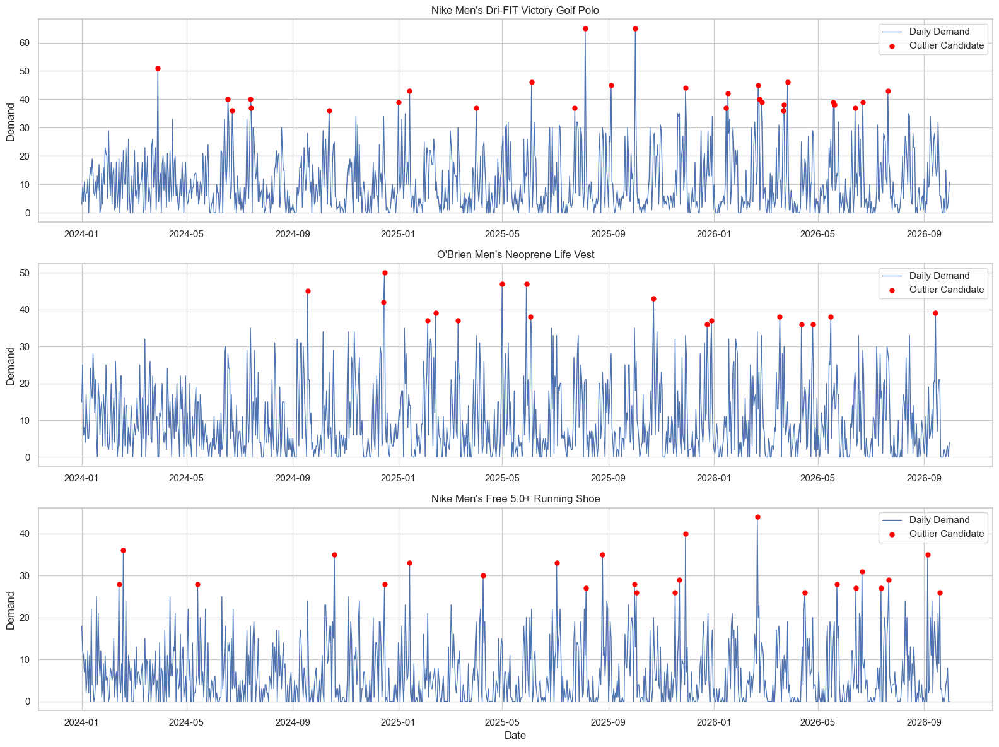

In [47]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 12)
)

for ax, product in zip(axes, PRODUCT_COLS):

    flag_col = f"{product}_outlier_flag"

    ax.plot(
        df[DATE_COL],
        df[product],
        label="Daily Demand",
        linewidth=1
    )

    flagged = df[outlier_flags[flag_col]]

    ax.scatter(
        flagged[DATE_COL],
        flagged[product],
        color="red",
        label="Outlier Candidate",
        s=25,
        zorder=3
    )

    ax.set_title(product)
    ax.set_ylabel("Demand")
    ax.legend()

plt.xlabel("Date")
plt.tight_layout()
plt.show()

# Data Preprocessing

## Remove Invalid Dates and Sort Data

In [48]:
preprocess_df = df.dropna(
    subset=[DATE_COL]
).copy()

# Normalize date values
preprocess_df[DATE_COL] = (
    preprocess_df[DATE_COL].dt.normalize()
)

# Ensure chronological order
preprocess_df = preprocess_df.sort_values(
    DATE_COL
).reset_index(drop=True)

# Stop if duplicate dates remain
if preprocess_df[DATE_COL].duplicated().any():

    raise ValueError(
        "Duplicate dates still exist. "
        "Please investigate them before continuing."
    )

print("Preprocessing preparation completed.")

display(preprocess_df.head())

Preprocessing preparation completed.


,Order Date,Nike Men's Dri-FIT Victory Golf Polo,O'Brien Men's Neoprene Life Vest,Nike Men's Free 5.0+ Running Shoe
0,2024-01-01,3.00,15.00,18.00
1,2024-01-02,9.00,25.00,12.00
2,2024-01-03,4.00,6.00,11.00
3,2024-01-04,11.00,8.00,7.00
4,2024-01-05,4.00,4.00,10.00


## Create Daily Time Series (Wide Format)

In [49]:
daily_wide = (
    preprocess_df
    .set_index(DATE_COL)[PRODUCT_COLS]
    .sort_index()
    .asfreq("D")
)

print("Daily Wide Dataset Shape:", daily_wide.shape)

display(daily_wide.head(10))

print("\nMissing Values After Date Alignment:")
display(daily_wide.isna().sum().to_frame("Missing Days"))

Daily Wide Dataset Shape: (1004, 3)


,Nike Men's Dri-FIT Victory Golf Polo,O'Brien Men's Neoprene Life Vest,Nike Men's Free 5.0+ Running Shoe
Order Date,,,
2024-01-01,3.00,15.00,18.00
2024-01-02,9.00,25.00,12.00
2024-01-03,4.00,6.00,11.00
2024-01-04,11.00,8.00,7.00
2024-01-05,4.00,4.00,10.00
2024-01-06,7.00,17.00,2.00
2024-01-07,7.00,10.00,5.00
2024-01-08,12.00,5.00,12.00
2024-01-09,0.00,5.00,2.00



Missing Values After Date Alignment:


,Missing Days
Nike Men's Dri-FIT Victory Golf Polo,0
O'Brien Men's Neoprene Life Vest,0
Nike Men's Free 5.0+ Running Shoe,0


## Convert Wide Format to Long Format

In [50]:
daily_long = (
    daily_wide
    .reset_index()
    .melt(
        id_vars=DATE_COL,
        value_vars=PRODUCT_COLS,
        var_name="product",
        value_name="demand"
    )
)

daily_long = daily_long.rename(
    columns={
        DATE_COL: "date"
    }
)

daily_long = daily_long.sort_values(
    ["product", "date"]
).reset_index(drop=True)

print("Daily Long Dataset Shape:", daily_long.shape)

display(daily_long.head(10))

Daily Long Dataset Shape: (3012, 3)


,date,product,demand
0,2024-01-01,Nike Men's Dri-FIT Victory Golf Polo,3.00
1,2024-01-02,Nike Men's Dri-FIT Victory Golf Polo,9.00
2,2024-01-03,Nike Men's Dri-FIT Victory Golf Polo,4.00
3,2024-01-04,Nike Men's Dri-FIT Victory Golf Polo,11.00
4,2024-01-05,Nike Men's Dri-FIT Victory Golf Polo,4.00
5,2024-01-06,Nike Men's Dri-FIT Victory Golf Polo,7.00
6,2024-01-07,Nike Men's Dri-FIT Victory Golf Polo,7.00
7,2024-01-08,Nike Men's Dri-FIT Victory Golf Polo,12.00
8,2024-01-09,Nike Men's Dri-FIT Victory Golf Polo,0.00
9,2024-01-10,Nike Men's Dri-FIT Victory Golf Polo,12.00


## Create Individual Product Time Series

In [51]:
series_by_product = {}

for product in PRODUCT_COLS:

    series_by_product[product] = (
        daily_wide[product]
        .rename("demand")
    )

for product, series in series_by_product.items():

    print(f"\nProduct: {product}")
    print("Start Date:", series.index.min())
    print("End Date:", series.index.max())
    print("Total Calendar Days:", len(series))
    print("Recorded Observations:", series.notna().sum())
    print("Missing Dates:", series.isna().sum())
    print("Zero Demand Days:", (series == 0).sum())


Product: Nike Men's Dri-FIT Victory Golf Polo
Start Date: 2024-01-01 00:00:00
End Date: 2026-09-30 00:00:00
Total Calendar Days: 1004
Recorded Observations: 1004
Missing Dates: 0
Zero Demand Days: 122

Product: O'Brien Men's Neoprene Life Vest
Start Date: 2024-01-01 00:00:00
End Date: 2026-09-30 00:00:00
Total Calendar Days: 1004
Recorded Observations: 1004
Missing Dates: 0
Zero Demand Days: 154

Product: Nike Men's Free 5.0+ Running Shoe
Start Date: 2024-01-01 00:00:00
End Date: 2026-09-30 00:00:00
Total Calendar Days: 1004
Recorded Observations: 1004
Missing Dates: 0
Zero Demand Days: 289


## Add Calendar Attributes for EDA

In [52]:
daily_long["day_of_week"] = (
    daily_long["date"].dt.dayofweek
)

daily_long["day_name"] = (
    daily_long["date"].dt.day_name()
)

daily_long["month"] = (
    daily_long["date"].dt.month
)

daily_long["month_name"] = (
    daily_long["date"].dt.month_name()
)

daily_long["year"] = (
    daily_long["date"].dt.year
)

daily_long["is_weekend"] = (
    daily_long["day_of_week"].isin([5, 6])
)

display(daily_long.head(10))

,date,product,demand,day_of_week,day_name,month,month_name,year,is_weekend
0,2024-01-01,Nike Men's Dri-FIT Victory Golf Polo,3.00,0,Monday,1,January,2024,False
1,2024-01-02,Nike Men's Dri-FIT Victory Golf Polo,9.00,1,Tuesday,1,January,2024,False
2,2024-01-03,Nike Men's Dri-FIT Victory Golf Polo,4.00,2,Wednesday,1,January,2024,False
3,2024-01-04,Nike Men's Dri-FIT Victory Golf Polo,11.00,3,Thursday,1,January,2024,False
4,2024-01-05,Nike Men's Dri-FIT Victory Golf Polo,4.00,4,Friday,1,January,2024,False
5,2024-01-06,Nike Men's Dri-FIT Victory Golf Polo,7.00,5,Saturday,1,January,2024,True
6,2024-01-07,Nike Men's Dri-FIT Victory Golf Polo,7.00,6,Sunday,1,January,2024,True
7,2024-01-08,Nike Men's Dri-FIT Victory Golf Polo,12.00,0,Monday,1,January,2024,False
8,2024-01-09,Nike Men's Dri-FIT Victory Golf Polo,0.00,1,Tuesday,1,January,2024,False
9,2024-01-10,Nike Men's Dri-FIT Victory Golf Polo,12.00,2,Wednesday,1,January,2024,False


## Attach Outlier Flags to Long Dataset

In [53]:
flag_data = outlier_flags.copy()

flag_data[DATE_COL] = df[DATE_COL]

flag_long = flag_data.melt(
    id_vars=DATE_COL,
    var_name="product_flag",
    value_name="outlier_flag"
)

flag_long["product"] = (
    flag_long["product_flag"]
    .str.replace("_outlier_flag", "", regex=False)
)

flag_long = flag_long.rename(
    columns={DATE_COL: "date"}
)

flag_long = flag_long[
    ["date", "product", "outlier_flag"]
]

daily_long = daily_long.merge(
    flag_long,
    on=["date", "product"],
    how="left"
)

display(daily_long.head(10))

,date,product,demand,day_of_week,day_name,month,month_name,year,is_weekend,outlier_flag
0,2024-01-01,Nike Men's Dri-FIT Victory Golf Polo,3.00,0,Monday,1,January,2024,False,False
1,2024-01-02,Nike Men's Dri-FIT Victory Golf Polo,9.00,1,Tuesday,1,January,2024,False,False
2,2024-01-03,Nike Men's Dri-FIT Victory Golf Polo,4.00,2,Wednesday,1,January,2024,False,False
3,2024-01-04,Nike Men's Dri-FIT Victory Golf Polo,11.00,3,Thursday,1,January,2024,False,False
4,2024-01-05,Nike Men's Dri-FIT Victory Golf Polo,4.00,4,Friday,1,January,2024,False,False
5,2024-01-06,Nike Men's Dri-FIT Victory Golf Polo,7.00,5,Saturday,1,January,2024,True,False
6,2024-01-07,Nike Men's Dri-FIT Victory Golf Polo,7.00,6,Sunday,1,January,2024,True,False
7,2024-01-08,Nike Men's Dri-FIT Victory Golf Polo,12.00,0,Monday,1,January,2024,False,False
8,2024-01-09,Nike Men's Dri-FIT Victory Golf Polo,0.00,1,Tuesday,1,January,2024,False,False
9,2024-01-10,Nike Men's Dri-FIT Victory Golf Polo,12.00,2,Wednesday,1,January,2024,False,False


# Exploratory Data Analysis (EDA)

## Descriptive Statistics per Product

In [54]:
eda_summary = (
    daily_long
    .groupby("product")
    .agg(
        Start_Date=("date", "min"),
        End_Date=("date", "max"),
        Calendar_Days=("date", "size"),
        Recorded_Days=("demand", "count"),
        Mean_Demand=("demand", "mean"),
        Median_Demand=("demand", "median"),
        Std_Demand=("demand", "std"),
        Min_Demand=("demand", "min"),
        Max_Demand=("demand", "max"),
        Total_Demand=("demand", "sum"),
        Zero_Demand_Days=(
            "demand",
            lambda x: (x == 0).sum()
        ),
        Outlier_Days=("outlier_flag", "sum")
    )
    .reset_index()
)

display(eda_summary)

,product,Start_Date,End_Date,Calendar_Days,Recorded_Days,Mean_Demand,Median_Demand,Std_Demand,Min_Demand,Max_Demand,Total_Demand,Zero_Demand_Days,Outlier_Days
0,Nike Men's Dri-FIT Victory Golf Polo,2024-01-01,2026-09-30,1004,1004,10.81,7.00,10.43,0.00,65.00,"10,852.00",122,28
1,Nike Men's Free 5.0+ Running Shoe,2024-01-01,2026-09-30,1004,1004,6.40,4.00,7.41,0.00,44.00,"6,426.00",289,24
2,O'Brien Men's Neoprene Life Vest,2024-01-01,2026-09-30,1004,1004,10.11,7.00,9.76,0.00,50.00,"10,154.00",154,17


## Daily Demand Visualization

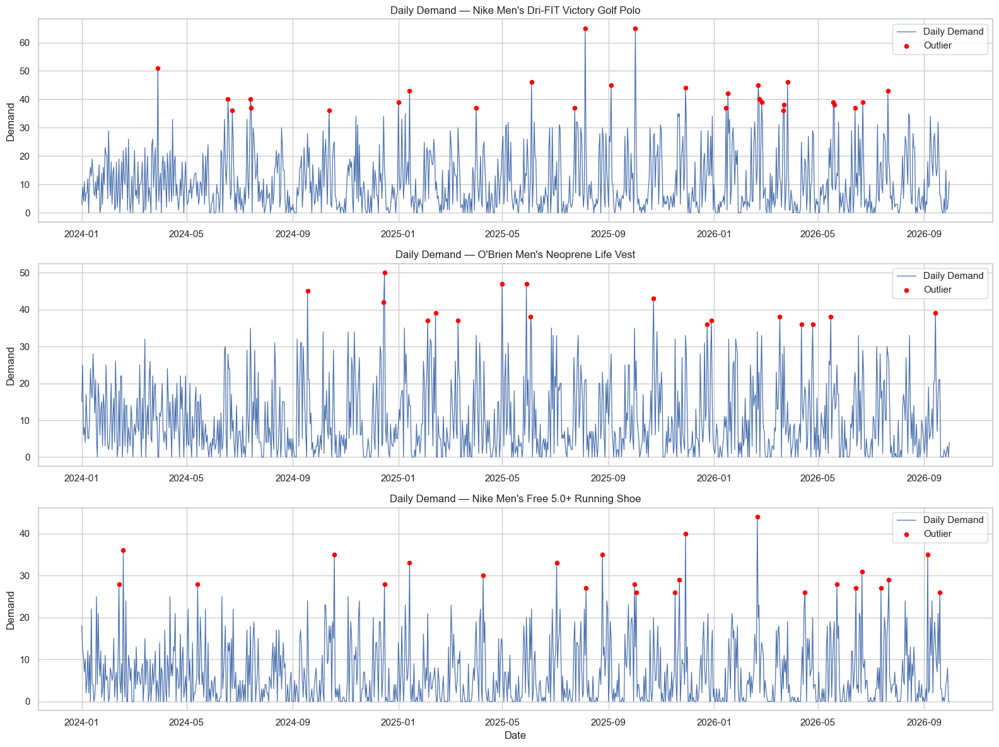

In [55]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 12)
)

for ax, product in zip(axes, PRODUCT_COLS):

    series = series_by_product[product]

    ax.plot(
        series.index,
        series.values,
        linewidth=0.9,
        label="Daily Demand"
    )

    flag_col = f"{product}_outlier_flag"

    flagged_dates = df.loc[
        outlier_flags[flag_col],
        DATE_COL
    ]

    flagged_values = df.loc[
        outlier_flags[flag_col],
        product
    ]

    ax.scatter(
        flagged_dates,
        flagged_values,
        color="red",
        s=20,
        label="Outlier",
        zorder=3
    )

    ax.set_title(f"Daily Demand — {product}")
    ax.set_ylabel("Demand")
    ax.legend()

plt.xlabel("Date")
plt.tight_layout()
plt.show()

## Monthly Demand Analysis

In [56]:
monthly_df = (
    daily_long
    .dropna(subset=["demand"])
    .assign(
        month_period=lambda x: (
            x["date"].dt.to_period("M")
        )
    )
    .groupby(
        ["product", "month_period"],
        as_index=False
    )["demand"]
    .sum()
)

monthly_df["month_date"] = (
    monthly_df["month_period"]
    .dt.to_timestamp()
)

display(monthly_df.head())

,product,month_period,demand,month_date
0,Nike Men's Dri-FIT Victory Golf Polo,2024-01,312.00,2024-01-01
1,Nike Men's Dri-FIT Victory Golf Polo,2024-02,313.00,2024-02-01
2,Nike Men's Dri-FIT Victory Golf Polo,2024-03,376.00,2024-03-01
3,Nike Men's Dri-FIT Victory Golf Polo,2024-04,344.00,2024-04-01
4,Nike Men's Dri-FIT Victory Golf Polo,2024-05,275.00,2024-05-01


## Monthly Demand Visualization

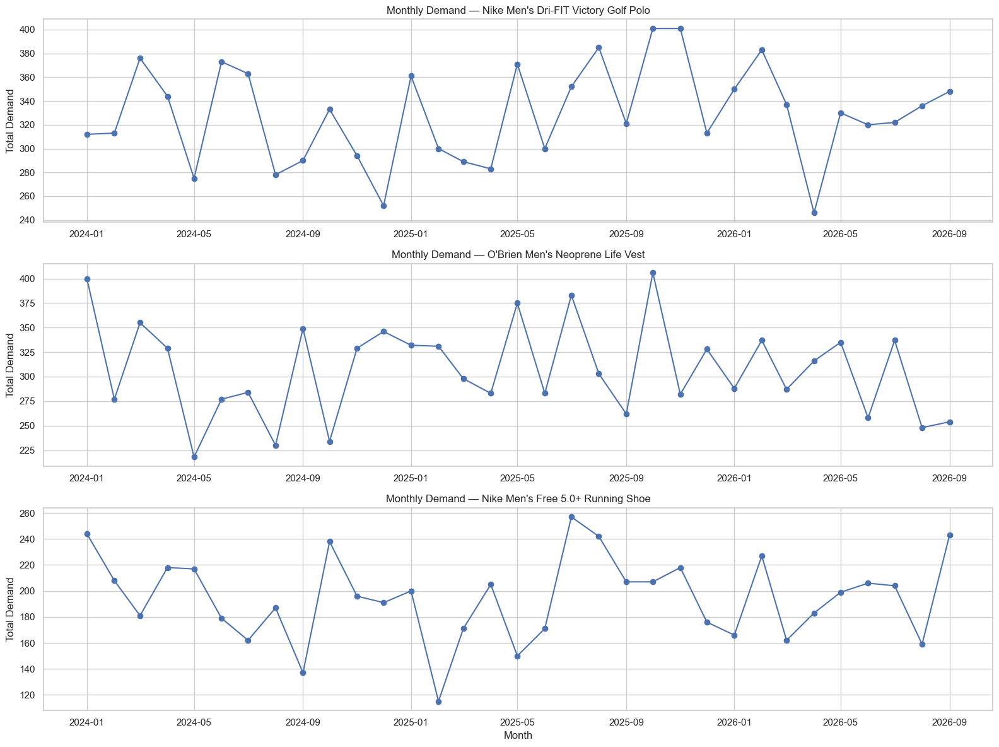

In [57]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(16, 12)
)

for ax, product in zip(axes, PRODUCT_COLS):

    product_data = monthly_df[
        monthly_df["product"] == product
    ]

    ax.plot(
        product_data["month_date"],
        product_data["demand"],
        marker="o"
    )

    ax.set_title(f"Monthly Demand — {product}")
    ax.set_ylabel("Total Demand")

plt.xlabel("Month")
plt.tight_layout()
plt.show()

## Day-of-Week Demand Analysis

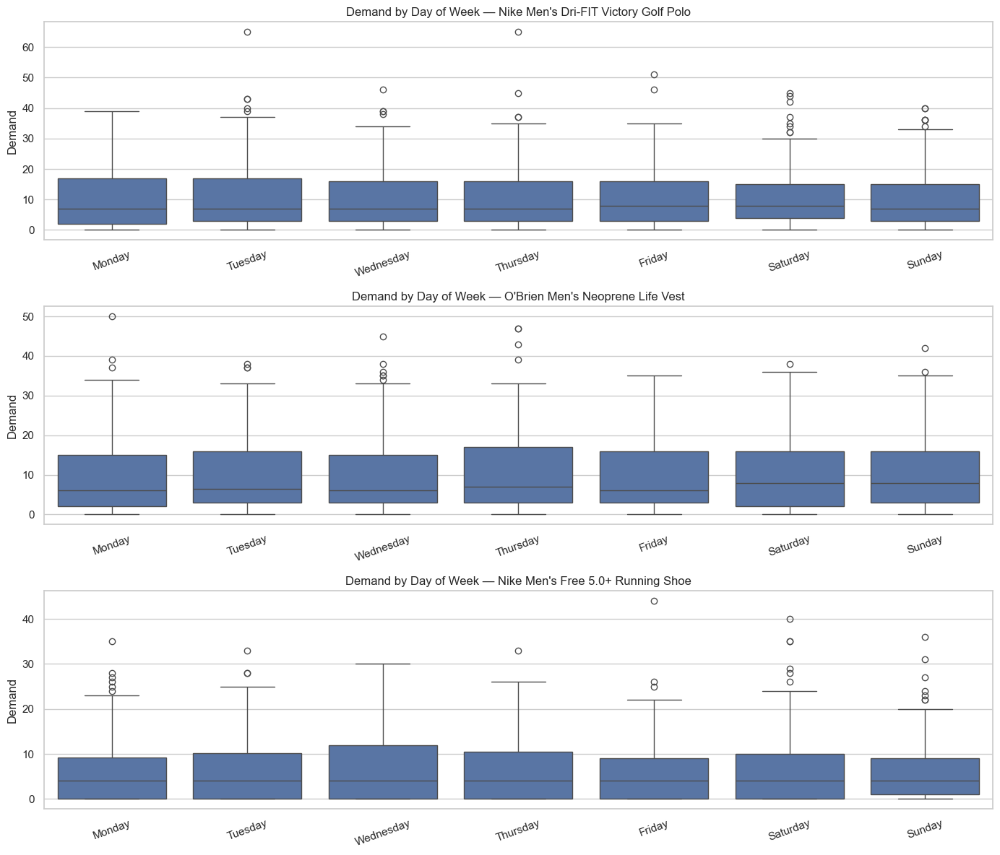

In [58]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 12)
)

for ax, product in zip(axes, PRODUCT_COLS):

    product_data = daily_long[
        daily_long["product"] == product
    ].dropna(subset=["demand"])

    sns.boxplot(
        data=product_data,
        x="day_name",
        y="demand",
        order=weekday_order,
        ax=ax
    )

    ax.set_title(f"Demand by Day of Week — {product}")
    ax.set_xlabel("")
    ax.set_ylabel("Demand")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Day-of-Week Average Demand

In [59]:
weekday_summary = (
    daily_long
    .dropna(subset=["demand"])
    .groupby(
        ["product", "day_of_week", "day_name"],
        as_index=False
    )
    .agg(
        Mean_Demand=("demand", "mean"),
        Median_Demand=("demand", "median"),
        Observation_Count=("demand", "count")
    )
    .sort_values(
        ["product", "day_of_week"]
    )
)

display(weekday_summary)

,product,day_of_week,day_name,Mean_Demand,Median_Demand,Observation_Count
0,Nike Men's Dri-FIT Victory Golf Polo,0,Monday,10.15,7.00,144
1,Nike Men's Dri-FIT Victory Golf Polo,1,Tuesday,11.26,7.00,144
2,Nike Men's Dri-FIT Victory Golf Polo,2,Wednesday,10.74,7.00,144
3,Nike Men's Dri-FIT Victory Golf Polo,3,Thursday,11.02,7.00,143
4,Nike Men's Dri-FIT Victory Golf Polo,4,Friday,10.78,8.00,143
5,Nike Men's Dri-FIT Victory Golf Polo,5,Saturday,11.03,8.00,143
6,Nike Men's Dri-FIT Victory Golf Polo,6,Sunday,10.66,7.00,143
7,Nike Men's Free 5.0+ Running Shoe,0,Monday,6.21,4.00,144
8,Nike Men's Free 5.0+ Running Shoe,1,Tuesday,6.42,4.00,144
9,Nike Men's Free 5.0+ Running Shoe,2,Wednesday,6.77,4.00,144


## Monthly Seasonality Analysis

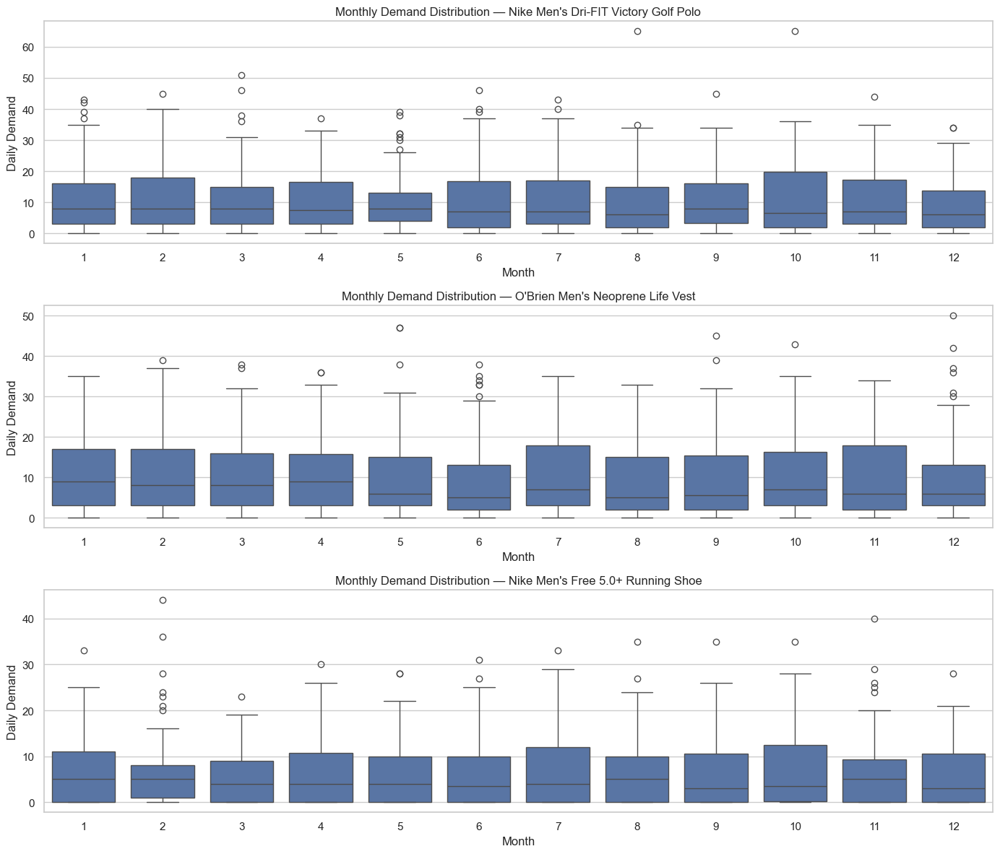

In [60]:
fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(14, 12)
)

for ax, product in zip(axes, PRODUCT_COLS):

    product_data = daily_long[
        daily_long["product"] == product
    ].dropna(subset=["demand"])

    sns.boxplot(
        data=product_data,
        x="month",
        y="demand",
        order=list(range(1, 13)),
        ax=ax
    )

    ax.set_title(f"Monthly Demand Distribution — {product}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Daily Demand")

plt.tight_layout()
plt.show()

## Rolling Mean Analysis

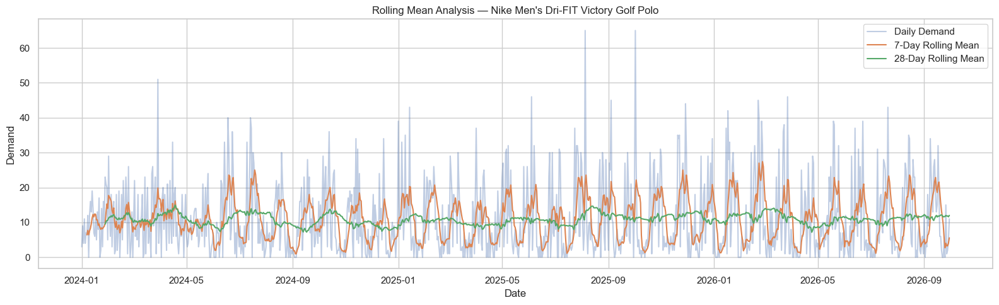

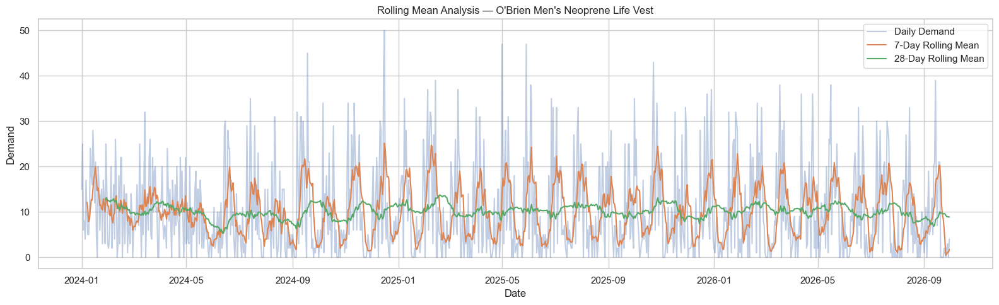

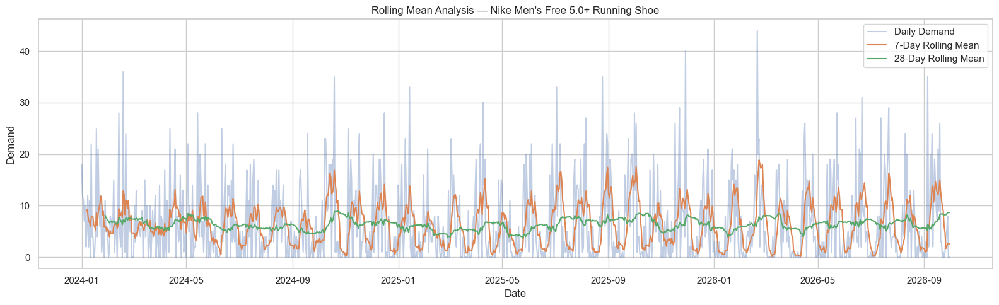

In [61]:
for product, series in series_by_product.items():

    rolling_mean_7 = series.rolling(
        window=7,
        min_periods=7
    ).mean()

    rolling_mean_28 = series.rolling(
        window=28,
        min_periods=28
    ).mean()

    plt.figure(figsize=(16, 5))

    plt.plot(
        series.index,
        series.values,
        alpha=0.35,
        label="Daily Demand"
    )

    plt.plot(
        rolling_mean_7.index,
        rolling_mean_7.values,
        label="7-Day Rolling Mean"
    )

    plt.plot(
        rolling_mean_28.index,
        rolling_mean_28.values,
        label="28-Day Rolling Mean"
    )

    plt.title(f"Rolling Mean Analysis — {product}")
    plt.xlabel("Date")
    plt.ylabel("Demand")
    plt.legend()

    plt.tight_layout()
    plt.show()

## Rolling Standard Deviation Analysis

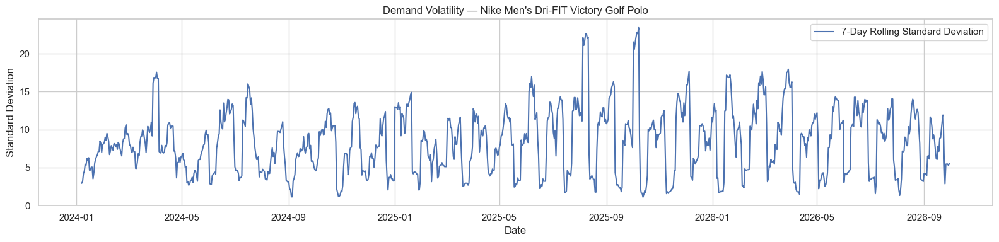

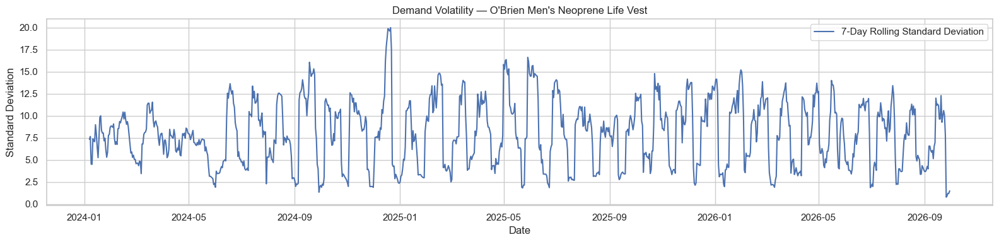

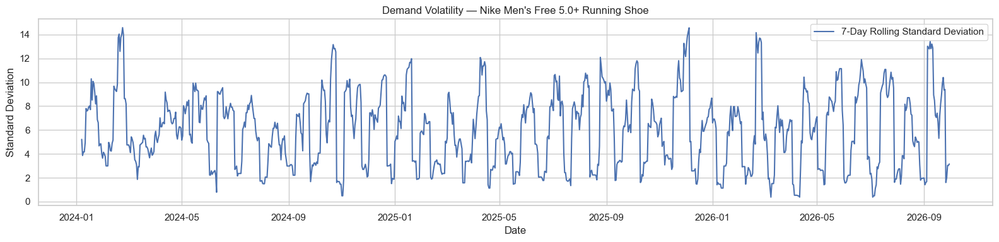

In [62]:
for product, series in series_by_product.items():

    rolling_std_7 = series.rolling(
        window=7,
        min_periods=7
    ).std()

    plt.figure(figsize=(16, 4))

    plt.plot(
        rolling_std_7.index,
        rolling_std_7.values,
        label="7-Day Rolling Standard Deviation"
    )

    plt.title(f"Demand Volatility — {product}")
    plt.xlabel("Date")
    plt.ylabel("Standard Deviation")
    plt.legend()

    plt.tight_layout()
    plt.show()

## Demand Distribution Analysis

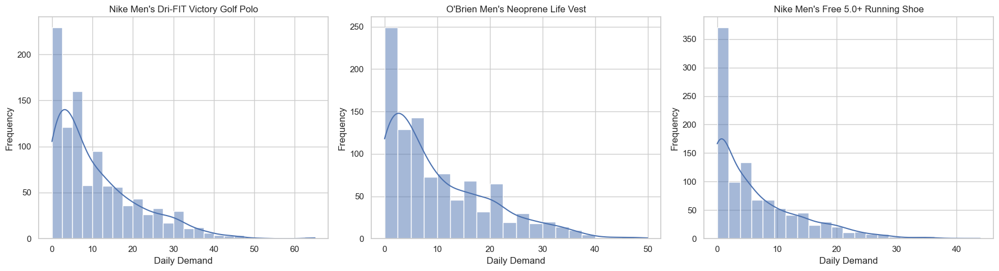

In [63]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5)
)

for ax, product in zip(axes, PRODUCT_COLS):

    demand = daily_wide[product].dropna()

    sns.histplot(
        demand,
        kde=True,
        ax=ax
    )

    ax.set_title(product)
    ax.set_xlabel("Daily Demand")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## Autocorrelation and Partial Autocorrelation Analysis

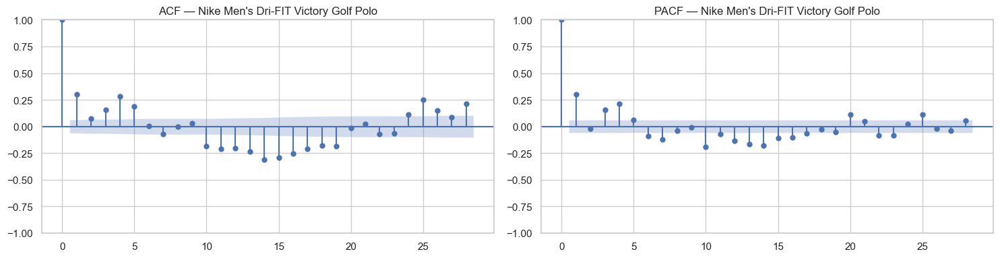

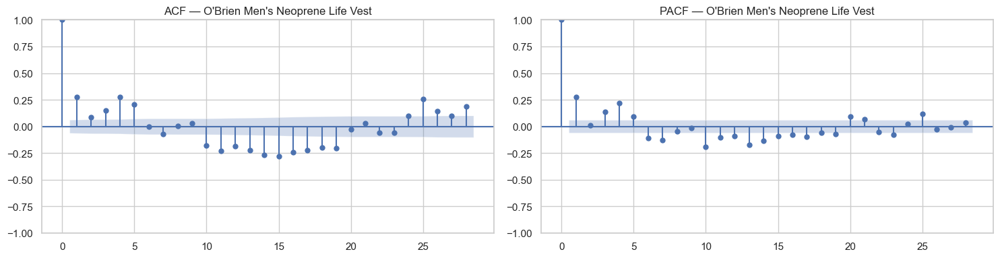

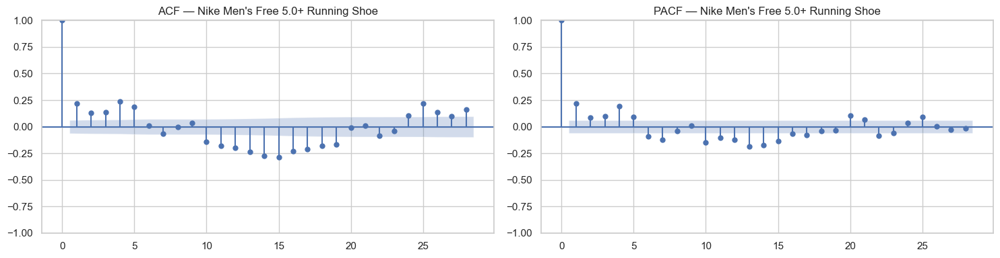

In [64]:
from statsmodels.graphics.tsaplots import (
    plot_acf,
    plot_pacf
)

for product, series in series_by_product.items():

    # Do not silently remove missing dates
    if series.isna().any():

        print(
            f"Skipping {product}: "
            "missing dates are still present."
        )

        continue

    if len(series) < 15:

        print(
            f"Skipping {product}: "
            "insufficient observations."
        )

        continue

    max_lags = min(
        28,
        len(series) // 2 - 1
    )

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(15, 4)
    )

    plot_acf(
        series,
        lags=max_lags,
        ax=axes[0]
    )

    plot_pacf(
        series,
        lags=max_lags,
        method="ywm",
        ax=axes[1]
    )

    axes[0].set_title(f"ACF — {product}")
    axes[1].set_title(f"PACF — {product}")

    plt.tight_layout()
    plt.show()

# Checkpoint Hasil EDA

## Final EDA Summary

In [65]:
print("=" * 70)
print("FINAL EDA SUMMARY")
print("=" * 70)

for product in PRODUCT_COLS:

    series = series_by_product[product]

    print(f"\nProduct: {product}")
    print("-" * 50)

    print("Observations:", series.notna().sum())
    print("Missing Dates:", series.isna().sum())
    print("Mean Demand:", series.mean())
    print("Median Demand:", series.median())
    print("Standard Deviation:", series.std())
    print("Minimum Demand:", series.min())
    print("Maximum Demand:", series.max())
    print("Zero Demand Days:", (series == 0).sum())

    flag_col = f"{product}_outlier_flag"

    print(
        "Outlier Candidates:",
        int(outlier_flags[flag_col].sum())
    )

print("\nEDA completed successfully.")

FINAL EDA SUMMARY

Product: Nike Men's Dri-FIT Victory Golf Polo
--------------------------------------------------
Observations: 1004
Missing Dates: 0
Mean Demand: 10.808764940239044
Median Demand: 7.0
Standard Deviation: 10.427993752750512
Minimum Demand: 0.0
Maximum Demand: 65.0
Zero Demand Days: 122
Outlier Candidates: 28

Product: O'Brien Men's Neoprene Life Vest
--------------------------------------------------
Observations: 1004
Missing Dates: 0
Mean Demand: 10.113545816733067
Median Demand: 7.0
Standard Deviation: 9.756101231699216
Minimum Demand: 0.0
Maximum Demand: 50.0
Zero Demand Days: 154
Outlier Candidates: 17

Product: Nike Men's Free 5.0+ Running Shoe
--------------------------------------------------
Observations: 1004
Missing Dates: 0
Mean Demand: 6.400398406374502
Median Demand: 4.0
Standard Deviation: 7.41485667710519
Minimum Demand: 0.0
Maximum Demand: 44.0
Zero Demand Days: 289
Outlier Candidates: 24

EDA completed successfully.


## Generate Comprehensive Data Analysis Report

In [66]:
# ============================================================
# COMPREHENSIVE DATA ANALYSIS REPORT
# Summary of Stages 01-05
# ============================================================

print("=" * 80)
print("DEMAND FORECASTING - COMPREHENSIVE DATA ANALYSIS REPORT")
print("=" * 80)

# ------------------------------------------------------------
# 1. DATASET INFORMATION
# ------------------------------------------------------------

print("\n[1] DATASET INFORMATION")
print("-" * 80)

print("Dataset Name       :", DATA_PATH.name)
print("Original Rows      :", len(raw_df))
print("Original Columns   :", len(raw_df.columns))
print("Number of Products :", len(PRODUCT_COLS))

print("Analysis Period    :", "2024-01-01 to 2026-09-30")

# Use data only through September 2026 for this report.
ANALYSIS_END_DATE = pd.Timestamp("2026-09-30")

report_data = daily_long[
    daily_long["date"] <= ANALYSIS_END_DATE
].copy()

report_data = report_data.sort_values(
    ["product", "date"]
)

print("Rows in Analysis  :", len(report_data))
print("Start Date        :", report_data["date"].min())
print("End Date          :", report_data["date"].max())


# ------------------------------------------------------------
# 2. DATA QUALITY SUMMARY
# ------------------------------------------------------------

print("\n[2] DATA QUALITY SUMMARY")
print("-" * 80)

print("Invalid Dates      :", df[DATE_COL].isna().sum())

print(
    "Duplicate Dates    :",
    df[DATE_COL].duplicated().sum()
)

print("\nMissing Values in Original Dataset:")

display(
    df[
        [DATE_COL] + PRODUCT_COLS
    ].isnull().sum().to_frame("Missing Count")
)

print("\nMissing Calendar Dates:")

analysis_calendar = pd.date_range(
    start="2024-01-01",
    end=ANALYSIS_END_DATE,
    freq="D"
)

recorded_dates = pd.DatetimeIndex(
    report_data["date"].dropna().unique()
)

missing_calendar_dates = analysis_calendar.difference(
    recorded_dates
)

print("Expected Calendar Days :", len(analysis_calendar))
print("Recorded Dates         :", len(recorded_dates))
print("Missing Dates          :", len(missing_calendar_dates))

print("\nFirst 15 Missing Dates:")
print(list(missing_calendar_dates[:15]))


# ------------------------------------------------------------
# 3. PRODUCT-LEVEL STATISTICS
# ------------------------------------------------------------

print("\n[3] PRODUCT-LEVEL STATISTICS")
print("-" * 80)

product_statistics = []

for product in PRODUCT_COLS:

    product_data = report_data[
        report_data["product"] == product
    ]

    demand = product_data["demand"].dropna()

    product_statistics.append({

        "Product": product,

        "Observations": len(demand),

        "Mean Demand": demand.mean(),

        "Median Demand": demand.median(),

        "Std Demand": demand.std(),

        "Min Demand": demand.min(),

        "Max Demand": demand.max(),

        "Total Demand": demand.sum(),

        "Zero Demand Days": (demand == 0).sum(),

        "Negative Demand Days": (demand < 0).sum(),

        "Missing Values": product_data["demand"].isna().sum()

    })

product_statistics_df = pd.DataFrame(
    product_statistics
)

display(product_statistics_df)


# ------------------------------------------------------------
# 4. OUTLIER ANALYSIS
# ------------------------------------------------------------

print("\n[4] OUTLIER ANALYSIS")
print("-" * 80)

outlier_report = []

for product in PRODUCT_COLS:

    product_data = report_data[
        report_data["product"] == product
    ]

    demand = product_data["demand"].dropna()

    Q1 = demand.quantile(0.25)
    Q3 = demand.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    flagged = (
        (demand < lower_bound) |
        (demand > upper_bound)
    )

    outlier_report.append({

        "Product": product,

        "Lower Bound": lower_bound,

        "Upper Bound": upper_bound,

        "Outlier Count": flagged.sum(),

        "Outlier Percentage": flagged.mean() * 100

    })

outlier_report_df = pd.DataFrame(
    outlier_report
)

display(outlier_report_df)


# ------------------------------------------------------------
# 5. WEEKDAY DEMAND ANALYSIS
# ------------------------------------------------------------

print("\n[5] WEEKDAY DEMAND ANALYSIS")
print("-" * 80)

weekday_report = (
    report_data
    .dropna(subset=["demand"])
    .groupby(["product", "day_name"])
    .agg(
        Mean_Demand=("demand", "mean"),
        Median_Demand=("demand", "median"),
        Observation_Count=("demand", "count")
    )
    .reset_index()
)

display(
    weekday_report.sort_values(
        ["product", "Mean_Demand"],
        ascending=[True, False]
    )
)


# ------------------------------------------------------------
# 6. MONTHLY DEMAND ANALYSIS
# ------------------------------------------------------------

print("\n[6] MONTHLY DEMAND ANALYSIS")
print("-" * 80)

monthly_report = (
    report_data
    .dropna(subset=["demand"])
    .assign(
        Year_Month=lambda x: x["date"].dt.to_period("M")
    )
    .groupby(
        ["product", "Year_Month"]
    )
    .agg(
        Total_Demand=("demand", "sum"),
        Average_Daily_Demand=("demand", "mean"),
        Observation_Count=("demand", "count")
    )
    .reset_index()
)

display(monthly_report)


# ------------------------------------------------------------
# 7. TIME SERIES CHARACTERISTICS
# ------------------------------------------------------------

print("\n[7] TIME SERIES CHARACTERISTICS")
print("-" * 80)

for product in PRODUCT_COLS:

    series = (
        report_data[
            report_data["product"] == product
        ]
        .set_index("date")["demand"]
        .sort_index()
        .asfreq("D")
    )

    print(f"\nProduct: {product}")

    print("Calendar Days       :", len(series))
    print("Recorded Observations:", series.notna().sum())
    print("Missing Dates       :", series.isna().sum())

    print("Mean Demand         :", round(series.mean(), 3))
    print("Standard Deviation  :", round(series.std(), 3))

    print("Zero Demand Days    :", (series == 0).sum())


# ------------------------------------------------------------
# 8. FINAL DATA READINESS
# ------------------------------------------------------------

print("\n[8] FINAL DATA READINESS")
print("-" * 80)

print("Products Included       :", len(PRODUCT_COLS))
print("Forecast Horizon        :", FORECAST_HORIZON, "days")
print("Multi-Step Strategy     : Direct")
print("ARIMA Configuration     : Basic ARIMA")
print("Outlier Treatment       : IQR Flagging")
print("Zero Demand Treatment   : Retained")
print("Missing Date Treatment  : Not Automatically Filled")
print("Analysis End Date       : 2026-09-30")

print("\n" + "=" * 80)
print("END OF COMPREHENSIVE DATA ANALYSIS REPORT")
print("=" * 80)

DEMAND FORECASTING - COMPREHENSIVE DATA ANALYSIS REPORT

[1] DATASET INFORMATION
--------------------------------------------------------------------------------
Dataset Name       : daily_sales_selected3_2024_2026.csv
Original Rows      : 1004
Original Columns   : 4
Number of Products : 3
Analysis Period    : 2024-01-01 to 2026-09-30
Rows in Analysis  : 3012
Start Date        : 2024-01-01 00:00:00
End Date          : 2026-09-30 00:00:00

[2] DATA QUALITY SUMMARY
--------------------------------------------------------------------------------
Invalid Dates      : 0
Duplicate Dates    : 0

Missing Values in Original Dataset:


,Missing Count
Order Date,0
Nike Men's Dri-FIT Victory Golf Polo,0
O'Brien Men's Neoprene Life Vest,0
Nike Men's Free 5.0+ Running Shoe,0



Missing Calendar Dates:
Expected Calendar Days : 1004
Recorded Dates         : 1004
Missing Dates          : 0

First 15 Missing Dates:
[]

[3] PRODUCT-LEVEL STATISTICS
--------------------------------------------------------------------------------


,Product,Observations,Mean Demand,Median Demand,Std Demand,Min Demand,Max Demand,Total Demand,Zero Demand Days,Negative Demand Days,Missing Values
0,Nike Men's Dri-FIT Victory Golf Polo,1004,10.81,7.00,10.43,0.00,65.00,"10,852.00",122,0,0
1,O'Brien Men's Neoprene Life Vest,1004,10.11,7.00,9.76,0.00,50.00,"10,154.00",154,0,0
2,Nike Men's Free 5.0+ Running Shoe,1004,6.40,4.00,7.41,0.00,44.00,"6,426.00",289,0,0



[4] OUTLIER ANALYSIS
--------------------------------------------------------------------------------


,Product,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Nike Men's Dri-FIT Victory Golf Polo,-16.50,35.50,28,2.79
1,O'Brien Men's Neoprene Life Vest,-16.50,35.50,17,1.69
2,Nike Men's Free 5.0+ Running Shoe,-15.00,25.00,24,2.39



[5] WEEKDAY DEMAND ANALYSIS
--------------------------------------------------------------------------------


,product,day_name,Mean_Demand,Median_Demand,Observation_Count
5,Nike Men's Dri-FIT Victory Golf Polo,Tuesday,11.26,7.00,144
2,Nike Men's Dri-FIT Victory Golf Polo,Saturday,11.03,8.00,143
4,Nike Men's Dri-FIT Victory Golf Polo,Thursday,11.02,7.00,143
0,Nike Men's Dri-FIT Victory Golf Polo,Friday,10.78,8.00,143
6,Nike Men's Dri-FIT Victory Golf Polo,Wednesday,10.74,7.00,144
3,Nike Men's Dri-FIT Victory Golf Polo,Sunday,10.66,7.00,143
1,Nike Men's Dri-FIT Victory Golf Polo,Monday,10.15,7.00,144
13,Nike Men's Free 5.0+ Running Shoe,Wednesday,6.77,4.00,144
9,Nike Men's Free 5.0+ Running Shoe,Saturday,6.76,4.00,143
12,Nike Men's Free 5.0+ Running Shoe,Tuesday,6.42,4.00,144



[6] MONTHLY DEMAND ANALYSIS
--------------------------------------------------------------------------------


,product,Year_Month,Total_Demand,Average_Daily_Demand,Observation_Count
0,Nike Men's Dri-FIT Victory Golf Polo,2024-01,312.00,10.06,31
1,Nike Men's Dri-FIT Victory Golf Polo,2024-02,313.00,10.79,29
2,Nike Men's Dri-FIT Victory Golf Polo,2024-03,376.00,12.13,31
3,Nike Men's Dri-FIT Victory Golf Polo,2024-04,344.00,11.47,30
4,Nike Men's Dri-FIT Victory Golf Polo,2024-05,275.00,8.87,31
...,...,...,...,...,...
94,O'Brien Men's Neoprene Life Vest,2026-05,335.00,10.81,31
95,O'Brien Men's Neoprene Life Vest,2026-06,258.00,8.60,30
96,O'Brien Men's Neoprene Life Vest,2026-07,337.00,10.87,31
97,O'Brien Men's Neoprene Life Vest,2026-08,248.00,8.00,31



[7] TIME SERIES CHARACTERISTICS
--------------------------------------------------------------------------------

Product: Nike Men's Dri-FIT Victory Golf Polo
Calendar Days       : 1004
Recorded Observations: 1004
Missing Dates       : 0
Mean Demand         : 10.809
Standard Deviation  : 10.428
Zero Demand Days    : 122

Product: O'Brien Men's Neoprene Life Vest
Calendar Days       : 1004
Recorded Observations: 1004
Missing Dates       : 0
Mean Demand         : 10.114
Standard Deviation  : 9.756
Zero Demand Days    : 154

Product: Nike Men's Free 5.0+ Running Shoe
Calendar Days       : 1004
Recorded Observations: 1004
Missing Dates       : 0
Mean Demand         : 6.4
Standard Deviation  : 7.415
Zero Demand Days    : 289

[8] FINAL DATA READINESS
--------------------------------------------------------------------------------
Products Included       : 3
Forecast Horizon        : 7 days
Multi-Step Strategy     : Direct
ARIMA Configuration     : Basic ARIMA
Outlier Treatment       : IQR

# 06. Feature Engineering

## Membuat Dataset Modeling

In [67]:
# menentukan periode data yang digunakan untuk modeling
MODEL_END_DATE = pd.Timestamp("2026-09-30")

# mengambil data sampai september 2026
df_model = df[df[DATE_COL] <= MODEL_END_DATE].copy()

# mengurutkan data berdasarkan tanggal
df_model = df_model.sort_values(DATE_COL).reset_index(drop=True)

# mengubah data menjadi format time series
model_daily_wide = (
    df_model
    .set_index(DATE_COL)[PRODUCT_COLS]
    .sort_index()
    .asfreq("D")
)

# memeriksa missing value
print("missing values:")
display(model_daily_wide.isna().sum())

# memeriksa periode modeling
print("\nperiode modeling:")
print(f"start date : {model_daily_wide.index.min()}")
print(f"end date   : {model_daily_wide.index.max()}")
print(f"total days : {len(model_daily_wide)}")

# memastikan tidak ada missing value
if model_daily_wide.isna().any().any():
    raise ValueError(
        "masih ada missing value pada data modeling"
    )

missing values:


Nike Men's Dri-FIT Victory Golf Polo    0
O'Brien Men's Neoprene Life Vest        0
Nike Men's Free 5.0+ Running Shoe       0
dtype: int64


periode modeling:
start date : 2024-01-01 00:00:00
end date   : 2026-09-30 00:00:00
total days : 1004


## Membuat Calendar, Lag, dan Rolling Features

In [68]:
# menentukan lag dan rolling window
LAG_PERIODS = [1, 2, 3, 7, 14, 28]
ROLLING_WINDOWS = [7, 14, 28]

# menentukan horizon yang digunakan
FORECAST_HORIZONS = [1, 3, 7]


def create_direct_features(series, horizon):

    data = pd.DataFrame(index=series.index)

    # menentukan tanggal target
    target_dates = series.index + pd.Timedelta(days=horizon)

    # membuat calendar features berdasarkan tanggal target
    data["day_of_week"] = target_dates.dayofweek
    data["day_of_month"] = target_dates.day
    data["month"] = target_dates.month
    data["day_of_year"] = target_dates.dayofyear
    data["is_weekend"] = (
        target_dates.dayofweek >= 5
    ).astype(int)

    # membuat lag features
    for lag in LAG_PERIODS:
        data[f"lag_{lag}"] = series.shift(lag - 1)

    # menggunakan demand sampai tanggal forecast origin
    historical_demand = series

    # membuat rolling statistics
    for window in ROLLING_WINDOWS:

        data[f"rolling_mean_{window}"] = (
            historical_demand
            .rolling(window=window)
            .mean()
        )

        data[f"rolling_std_{window}"] = (
            historical_demand
            .rolling(window=window)
            .std()
        )

    # menambahkan target demand dan tanggal target
    data["target"] = series.shift(-horizon)
    data["target_date"] = target_dates

    # menghapus baris yang belum memiliki fitur lengkap atau target
    data = data.dropna().copy()

    return data


print("feature engineering function berhasil dibuat")

feature engineering function berhasil dibuat


## Membuat Dataset Direct untuk Tiga Horizon

In [69]:
# membuat dataset direct untuk semua produk
direct_datasets = {}

for product in PRODUCT_COLS:

    series = model_daily_wide[product]

    direct_datasets[product] = {}

    for horizon in FORECAST_HORIZONS:

        dataset = create_direct_features(
            series=series,
            horizon=horizon
        )

        direct_datasets[product][horizon] = dataset


print("dataset direct berhasil dibuat")

for product in PRODUCT_COLS:

    print(f"\nproduk: {product}")

    for horizon, dataset in direct_datasets[product].items():

        print(
            f"H+{horizon}: "
            f"{len(dataset)} observations"
        )

dataset direct berhasil dibuat

produk: Nike Men's Dri-FIT Victory Golf Polo
H+1: 976 observations
H+3: 974 observations
H+7: 970 observations

produk: O'Brien Men's Neoprene Life Vest
H+1: 976 observations
H+3: 974 observations
H+7: 970 observations

produk: Nike Men's Free 5.0+ Running Shoe
H+1: 976 observations
H+3: 974 observations
H+7: 970 observations


## Memeriksa Hasil Feature Engineering

In [70]:
# memilih salah satu produk dan horizon untuk diperiksa
selected_product = PRODUCT_COLS[0]
selected_horizon = 1

sample_features = direct_datasets[
    selected_product
][selected_horizon]

print("selected product:")
print(selected_product)

print("\nselected horizon:")
print(f"H+{selected_horizon}")

print("\nfeature dataset:")
display(sample_features.head(10))

print("\nfeature columns:")
print(sample_features.columns.tolist())

print("\ndataset information:")
sample_features.info()

selected product:
Nike Men's Dri-FIT Victory Golf Polo

selected horizon:
H+1

feature dataset:


,day_of_week,day_of_month,month,day_of_year,is_weekend,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,rolling_mean_7,rolling_std_7,rolling_mean_14,rolling_std_14,rolling_mean_28,rolling_std_28,target,target_date
Order Date,,,,,,,,,,,,,,,,,,,
2024-01-28,0,29,1,29,0,23.00,10.00,16.00,0.00,7.00,3.00,9.71,8.50,9.64,6.48,9.50,5.87,21.00,2024-01-29
2024-01-29,1,30,1,30,0,21.00,23.00,10.00,2.00,6.00,9.00,12.71,8.20,10.64,7.09,10.14,6.11,20.00,2024-01-30
2024-01-30,2,31,1,31,0,20.00,21.00,23.00,14.00,11.00,4.00,15.29,7.02,11.64,7.37,10.54,6.39,5.00,2024-01-31
2024-01-31,3,1,2,32,0,5.00,20.00,21.00,3.00,5.00,11.00,14.00,8.04,11.21,7.58,10.57,6.35,29.00,2024-02-01
2024-02-01,4,2,2,33,0,29.00,5.00,20.00,16.00,13.00,4.00,17.71,8.12,12.93,8.70,11.21,7.24,13.00,2024-02-02
2024-02-02,5,3,2,34,1,13.00,29.00,5.00,10.00,8.00,7.00,17.29,8.30,12.93,8.70,11.54,7.11,6.00,2024-02-03
2024-02-03,6,4,2,35,1,6.00,13.00,29.00,23.00,17.00,7.00,16.71,8.99,12.79,8.80,11.50,7.14,18.00,2024-02-04
2024-02-04,0,5,2,36,0,18.00,6.00,13.00,21.00,0.00,12.00,16.00,8.60,12.86,8.84,11.89,7.18,3.00,2024-02-05
2024-02-05,1,6,2,37,0,3.00,18.00,6.00,20.00,2.00,0.00,13.43,9.50,13.07,8.53,11.57,7.38,14.00,2024-02-06



feature columns:
['day_of_week', 'day_of_month', 'month', 'day_of_year', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_mean_28', 'rolling_std_28', 'target', 'target_date']

dataset information:
<class 'pandas.DataFrame'>
DatetimeIndex: 976 entries, 2024-01-28 to 2026-09-29
Freq: D
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   day_of_week      976 non-null    int32         
 1   day_of_month     976 non-null    int32         
 2   month            976 non-null    int32         
 3   day_of_year      976 non-null    int32         
 4   is_weekend       976 non-null    int32         
 5   lag_1            976 non-null    float64       
 6   lag_2            976 non-null    float64       
 7   lag_3            976 non-null    float64       
 8   lag_7            976 non-null    float64    

## Visualisasi Beberapa Fitur

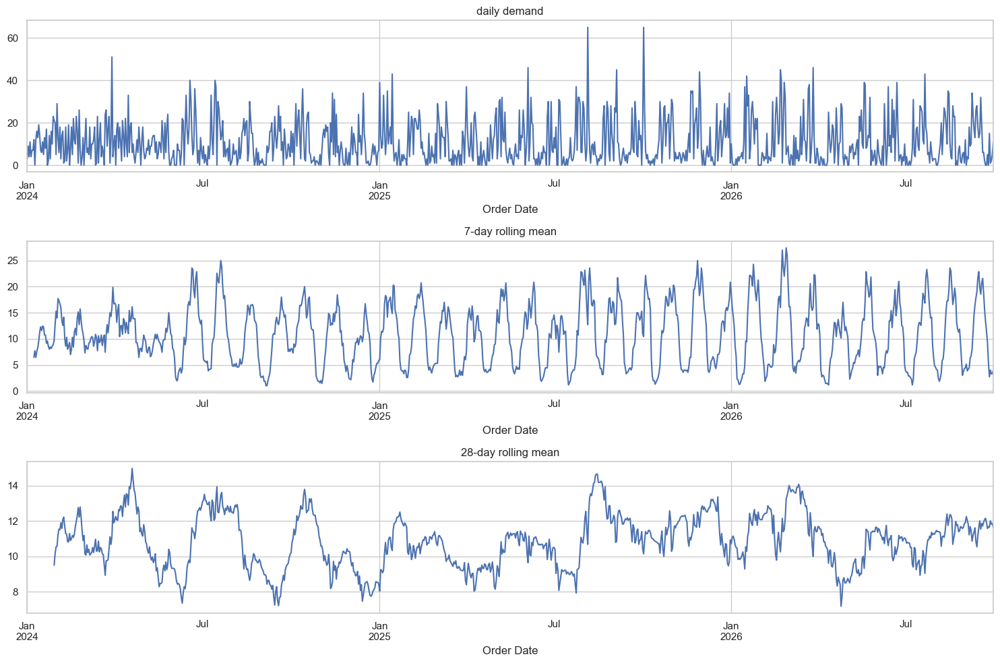

In [71]:
# mengambil data salah satu produk
selected_product = PRODUCT_COLS[0]

sample_series = model_daily_wide[selected_product]

# membuat visualisasi demand dan rolling mean
fig, axes = plt.subplots(3, 1, figsize=(15, 10))

sample_series.plot(
    ax=axes[0],
    title="daily demand"
)

sample_series.shift(1).rolling(7).mean().plot(
    ax=axes[1],
    title="7-day rolling mean"
)

sample_series.shift(1).rolling(28).mean().plot(
    ax=axes[2],
    title="28-day rolling mean"
)

plt.tight_layout()
plt.show()

# 07. Train-Validation-Test Split

## Menentukan Temporal Split

In [72]:
# menentukan proporsi pembagian data
TRAIN_RATIO = 0.70
VALIDATION_RATIO = 0.15
TEST_RATIO = 0.15

# menentukan batas tanggal berdasarkan data harian
n = len(model_daily_wide)

train_end = int(n * TRAIN_RATIO)

validation_end = int(
    n * (TRAIN_RATIO + VALIDATION_RATIO)
)

train_cutoff = model_daily_wide.index[train_end - 1]

validation_cutoff = model_daily_wide.index[
    validation_end - 1
]

# menyimpan hasil split setiap produk dan horizon
direct_splits = {}

for product in PRODUCT_COLS:

    direct_splits[product] = {}

    for horizon, dataset in direct_datasets[product].items():

        dataset = dataset.sort_values(
            "target_date"
        ).copy()

        # membagi data berdasarkan tanggal target
        train_data = dataset[
            dataset["target_date"] <= train_cutoff
        ].copy()

        validation_data = dataset[
            (
                dataset["target_date"] > train_cutoff
            )
            &
            (
                dataset["target_date"] <= validation_cutoff
            )
        ].copy()

        test_data = dataset[
            dataset["target_date"] > validation_cutoff
        ].copy()

        direct_splits[product][horizon] = {
            "train": train_data,
            "validation": validation_data,
            "test": test_data
        }


print("temporal split berhasil dibuat")

print(f"train cutoff      : {train_cutoff.date()}")
print(f"validation cutoff : {validation_cutoff.date()}")
print(f"test dimulai      : {(validation_cutoff + pd.Timedelta(days=1)).date()}")

temporal split berhasil dibuat
train cutoff      : 2025-12-02
validation cutoff : 2026-05-02
test dimulai      : 2026-05-03


## Ringkasan Temporal Split

In [73]:
# membuat ringkasan hasil pembagian data
split_summary = []

for product in PRODUCT_COLS:

    for horizon, split in direct_splits[product].items():

        for split_name, split_data in split.items():

            split_summary.append({
                "Product": product,
                "Horizon": f"H+{horizon}",
                "Split": split_name,
                "Observations": len(split_data),
                "Start Date": split_data["target_date"].min(),
                "End Date": split_data["target_date"].max()
            })


split_summary_df = pd.DataFrame(split_summary)

display(split_summary_df)

,Product,Horizon,Split,Observations,Start Date,End Date
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,train,674,2024-01-29,2025-12-02
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,validation,151,2025-12-03,2026-05-02
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,test,151,2026-05-03,2026-09-30
3,Nike Men's Dri-FIT Victory Golf Polo,H+3,train,672,2024-01-31,2025-12-02
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,validation,151,2025-12-03,2026-05-02
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,test,151,2026-05-03,2026-09-30
6,Nike Men's Dri-FIT Victory Golf Polo,H+7,train,668,2024-02-04,2025-12-02
7,Nike Men's Dri-FIT Victory Golf Polo,H+7,validation,151,2025-12-03,2026-05-02
8,Nike Men's Dri-FIT Victory Golf Polo,H+7,test,151,2026-05-03,2026-09-30
9,O'Brien Men's Neoprene Life Vest,H+1,train,674,2024-01-29,2025-12-02


## Menyiapkan Walk-Forward Validation

In [74]:
# mengimpor time series split
from sklearn.model_selection import TimeSeriesSplit

# menentukan jumlah fold
N_SPLITS = 3


def create_walk_forward_splits(
    data,
    n_splits=N_SPLITS
):

    splitter = TimeSeriesSplit(
        n_splits=n_splits
    )

    splits = []

    for train_idx, validation_idx in splitter.split(data):

        splits.append({
            "train_idx": train_idx,
            "validation_idx": validation_idx
        })

    return splits


# mencoba walk-forward pada salah satu dataset
sample_data = direct_splits[
    PRODUCT_COLS[0]
][1]["train"]

walk_forward_folds = create_walk_forward_splits(
    sample_data
)

print(f"jumlah folds: {len(walk_forward_folds)}")

for i, fold in enumerate(walk_forward_folds, start=1):

    print(f"\nfold {i}")
    print(f"training observations   : {len(fold['train_idx'])}")
    print(f"validation observations : {len(fold['validation_idx'])}")

jumlah folds: 3

fold 1
training observations   : 170
validation observations : 168

fold 2
training observations   : 338
validation observations : 168

fold 3
training observations   : 506
validation observations : 168


## Menyiapkan Fungsi Evaluasi

In [75]:
# mengimpor metrik evaluasi
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)


def calculate_metrics(y_true, y_pred):

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    total_actual = np.sum(
        np.abs(y_true)
    )

    if total_actual == 0:

        wape = np.nan

    else:

        wape = (
            np.sum(np.abs(y_true - y_pred))
            / total_actual
        ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape
    }


# menghitung rata-rata mae dari walk-forward validation
def walk_forward_score(
    estimator,
    X,
    y,
    n_splits=N_SPLITS
):

    splitter = TimeSeriesSplit(
        n_splits=n_splits
    )

    fold_scores = []

    for train_idx, validation_idx in splitter.split(X):

        X_train_fold = X.iloc[train_idx]
        y_train_fold = y.iloc[train_idx]

        X_validation_fold = X.iloc[validation_idx]
        y_validation_fold = y.iloc[validation_idx]

        # melatih model pada fold saat ini
        estimator.fit(
            X_train_fold,
            y_train_fold
        )

        # melakukan prediksi pada validation fold
        predictions = estimator.predict(
            X_validation_fold
        )

        # menghitung mae
        fold_mae = mean_absolute_error(
            y_validation_fold,
            predictions
        )

        fold_scores.append(fold_mae)

    return np.mean(fold_scores)


print("fungsi evaluasi berhasil dibuat")

fungsi evaluasi berhasil dibuat


## Menyiapkan Fungsi Dataset Model

In [76]:
# menentukan kolom yang digunakan sebagai fitur
FEATURE_COLUMNS = [
    col
    for col in direct_datasets[
        PRODUCT_COLS[0]
    ][1].columns
    if col not in ["target", "target_date"]
]


# memisahkan fitur dan target
def get_xy(data):

    X = data[FEATURE_COLUMNS].copy()
    y = data["target"].copy()

    return X, y


print("feature columns:")
print(FEATURE_COLUMNS)

print(f"\ntotal features: {len(FEATURE_COLUMNS)}")

feature columns:
['day_of_week', 'day_of_month', 'month', 'day_of_year', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_14', 'rolling_std_14', 'rolling_mean_28', 'rolling_std_28']

total features: 17


# 08. ARIMA Modeling

## Import Library ARIMA

In [77]:
# mengimpor library arima
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# mengimpor library pendukung
import itertools
import warnings

warnings.filterwarnings("ignore")

## Stationarity Test

In [78]:
# menyiapkan hasil pengujian stationarity
arima_split_points = {}
stationarity_results = []

for product in PRODUCT_COLS:

    series = model_daily_wide[product].dropna()

    # mengambil data training saja
    train_series = series[
        series.index <= train_cutoff
    ]

    arima_split_points[product] = {
        "train_end": len(train_series),
        "total": len(series)
    }

    # melakukan pengujian adf
    adf_result = adfuller(
        train_series
    )

    p_value = adf_result[1]

    stationarity_results.append({
        "Product": product,
        "ADF Statistic": adf_result[0],
        "p-value": p_value,
        "Stationarity": (
            "Stationary"
            if p_value < 0.05
            else "Non-Stationary"
        )
    })


stationarity_df = pd.DataFrame(
    stationarity_results
)

display(stationarity_df)

,Product,ADF Statistic,p-value,Stationarity
0,Nike Men's Dri-FIT Victory Golf Polo,-8.73,0.00,Stationary
1,O'Brien Men's Neoprene Life Vest,-7.88,0.00,Stationary
2,Nike Men's Free 5.0+ Running Shoe,-7.19,0.00,Stationary


## Pemilihan Parameter ARIMA

In [79]:
# menentukan kandidat parameter arima
p_values = [0, 1, 2]
d_values = [0, 1]
q_values = [0, 1, 2]

arima_orders = list(
    itertools.product(
        p_values,
        d_values,
        q_values
    )
)

# menyiapkan tempat hasil pemilihan parameter
best_arima_orders = {}
arima_order_results = []

for product in PRODUCT_COLS:

    series = model_daily_wide[product]

    # menggunakan data training saja
    train_series = series[
        series.index <= train_cutoff
    ]

    best_aic = np.inf
    best_order = None

    for order in arima_orders:

        if order == (0, 0, 0):
            continue

        try:

            model = ARIMA(
                train_series,
                order=order
            )

            fitted_model = model.fit()

            aic = fitted_model.aic

            arima_order_results.append({
                "Product": product,
                "Order": order,
                "AIC": aic
            })

            if aic < best_aic:

                best_aic = aic
                best_order = order

        except Exception:

            continue

    if best_order is None:

        raise ValueError(
            f"tidak ditemukan parameter arima untuk {product}"
        )

    best_arima_orders[product] = best_order

    print(
        f"{product}: "
        f"best order = {best_order}, "
        f"AIC = {best_aic:.2f}"
    )


arima_order_results_df = pd.DataFrame(
    arima_order_results
)

print("\nringkasan parameter terbaik:")
display(
    pd.DataFrame([
        {
            "Product": product,
            "Best ARIMA Order": order
        }
        for product, order in best_arima_orders.items()
    ])
)

Nike Men's Dri-FIT Victory Golf Polo: best order = (2, 0, 2), AIC = 5181.91
O'Brien Men's Neoprene Life Vest: best order = (2, 0, 2), AIC = 5136.82
Nike Men's Free 5.0+ Running Shoe: best order = (2, 0, 2), AIC = 4650.35

ringkasan parameter terbaik:


,Product,Best ARIMA Order
0,Nike Men's Dri-FIT Victory Golf Polo,"(2, 0, 2)"
1,O'Brien Men's Neoprene Life Vest,"(2, 0, 2)"
2,Nike Men's Free 5.0+ Running Shoe,"(2, 0, 2)"


## Membuat Fungsi Rolling ARIMA Forecast

In [80]:
# membuat fungsi rolling forecast untuk arima
def rolling_arima_evaluation(
    series,
    order,
    target_start,
    target_end,
    horizons=FORECAST_HORIZONS,
    min_history=30
):

    values = np.asarray(series)
    dates = series.index

    predictions = {
        horizon: []
        for horizon in horizons
    }

    actuals = {
        horizon: []
        for horizon in horizons
    }

    forecast_dates = {
        horizon: []
        for horizon in horizons
    }

    max_horizon = max(horizons)

    # melakukan forecasting dari setiap origin
    for origin in range(
        min_history - 1,
        len(values) - max_horizon
    ):

        history = values[:origin + 1]

        # memeriksa apakah masih ada data histori
        if len(history) < min_history:
            continue

        try:

            model = ARIMA(
                history,
                order=order
            )

            fitted_model = model.fit()

            # memprediksi sampai tujuh hari ke depan
            forecast = fitted_model.forecast(
                steps=max_horizon
            )

            # mengambil prediksi pada setiap horizon
            for horizon in horizons:

                target_position = origin + horizon

                target_date = dates[target_position]

                # hanya menyimpan target pada periode evaluasi
                if (
                    target_start
                    <= target_date
                    <= target_end
                ):

                    predictions[horizon].append(
                        float(forecast[horizon - 1])
                    )

                    actuals[horizon].append(
                        float(values[target_position])
                    )

                    forecast_dates[horizon].append(
                        target_date
                    )

        except Exception:

            continue

    # menyusun hasil evaluasi setiap horizon
    results = {}

    for horizon in horizons:

        results[horizon] = pd.DataFrame({
            "date": forecast_dates[horizon],
            "actual": actuals[horizon],
            "prediction": predictions[horizon]
        })

    return results

## Training dan Evaluasi ARIMA

In [81]:
# menyiapkan tempat hasil arima
arima_validation_results = {}
arima_test_results = {}

arima_metrics = []

for product in PRODUCT_COLS:

    series = model_daily_wide[product]

    order = best_arima_orders[product]

    # evaluasi validation
    validation_result = rolling_arima_evaluation(
        series=series,
        order=order,
        target_start=train_cutoff + pd.Timedelta(days=1),
        target_end=validation_cutoff
    )

    # evaluasi test
    test_result = rolling_arima_evaluation(
        series=series,
        order=order,
        target_start=validation_cutoff + pd.Timedelta(days=1),
        target_end=MODEL_END_DATE
    )

    arima_validation_results[product] = validation_result
    arima_test_results[product] = test_result

    # menghitung metrik setiap horizon
    for horizon in FORECAST_HORIZONS:

        validation_data = validation_result[horizon]
        test_data = test_result[horizon]

        validation_metrics = calculate_metrics(
            validation_data["actual"],
            validation_data["prediction"]
        )

        test_metrics = calculate_metrics(
            test_data["actual"],
            test_data["prediction"]
        )

        arima_metrics.append({
            "Product": product,
            "Horizon": f"H+{horizon}",
            "Validation MAE": validation_metrics["MAE"],
            "Validation RMSE": validation_metrics["RMSE"],
            "Validation WAPE": validation_metrics["WAPE"],
            "Test MAE": test_metrics["MAE"],
            "Test RMSE": test_metrics["RMSE"],
            "Test WAPE": test_metrics["WAPE"]
        })


arima_results_df = pd.DataFrame(
    arima_metrics
)

display(arima_results_df)

,Product,Horizon,Validation MAE,Validation RMSE,Validation WAPE,Test MAE,Test RMSE,Test WAPE
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,8.52,10.87,79.06,7.65,9.90,68.60
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,9.16,11.38,85.01,8.27,10.40,74.46
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,9.53,11.74,88.43,8.56,10.73,78.23
3,O'Brien Men's Neoprene Life Vest,H+1,7.59,9.72,73.80,7.13,8.70,73.13
4,O'Brien Men's Neoprene Life Vest,H+3,7.97,9.90,77.55,7.63,9.25,79.29
5,O'Brien Men's Neoprene Life Vest,H+7,8.06,10.09,78.40,7.98,9.51,84.61
6,Nike Men's Free 5.0+ Running Shoe,H+1,4.10,5.77,68.18,4.85,7.00,71.39
7,Nike Men's Free 5.0+ Running Shoe,H+3,4.12,5.77,68.46,4.79,6.92,71.00
8,Nike Men's Free 5.0+ Running Shoe,H+7,4.21,5.84,70.03,4.74,6.86,71.32


## Visualisasi Hasil ARIMA

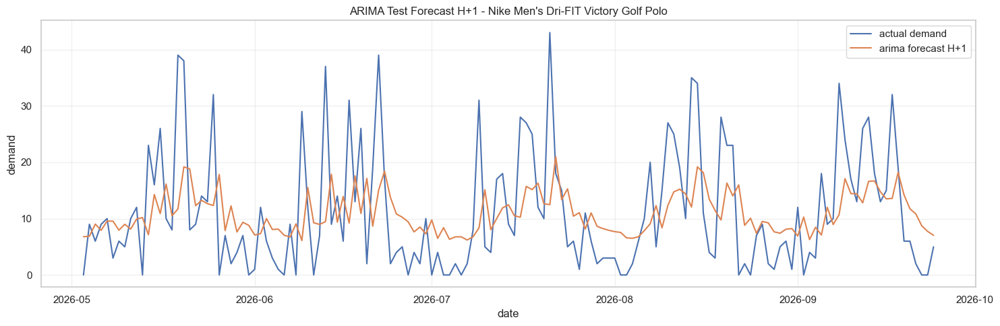

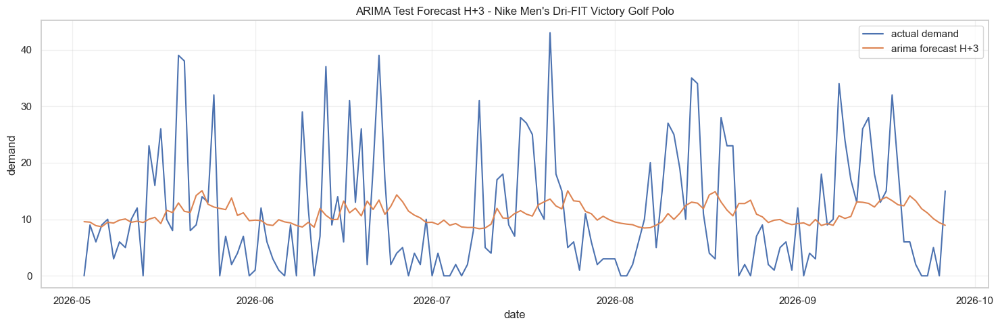

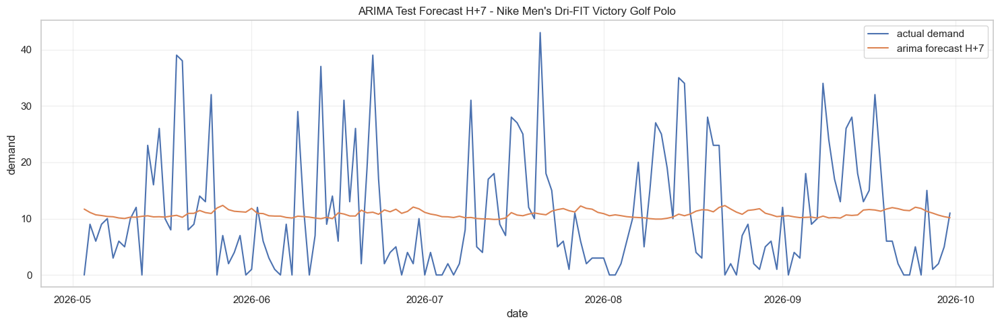

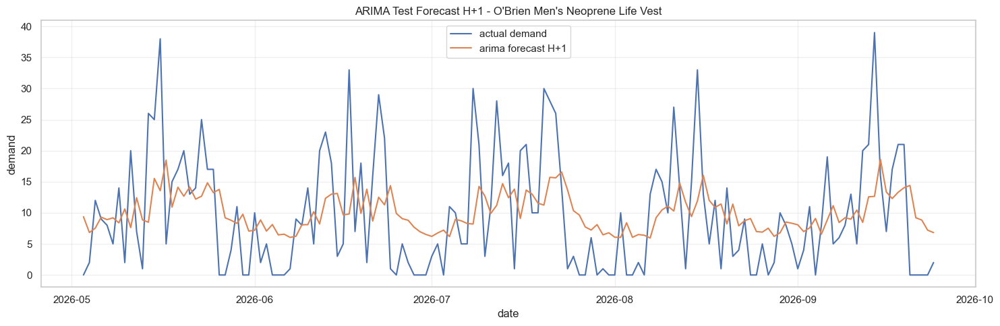

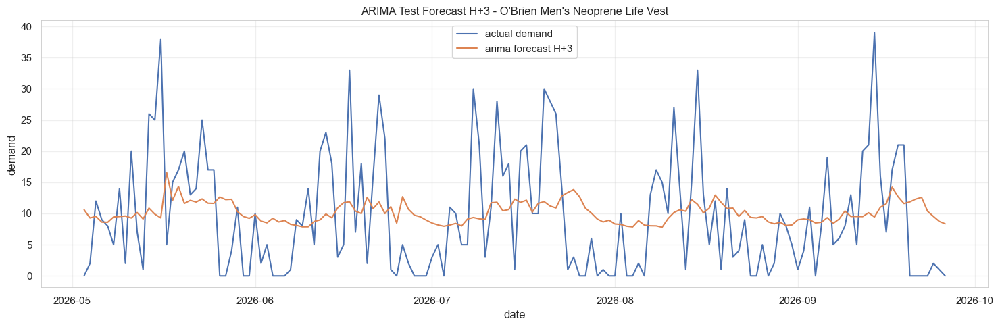

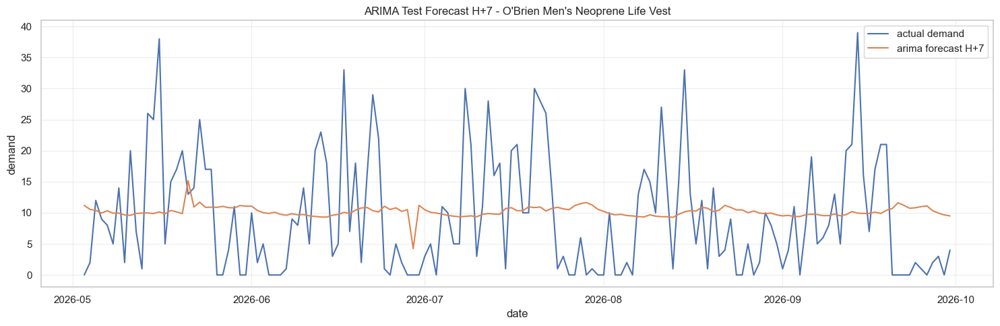

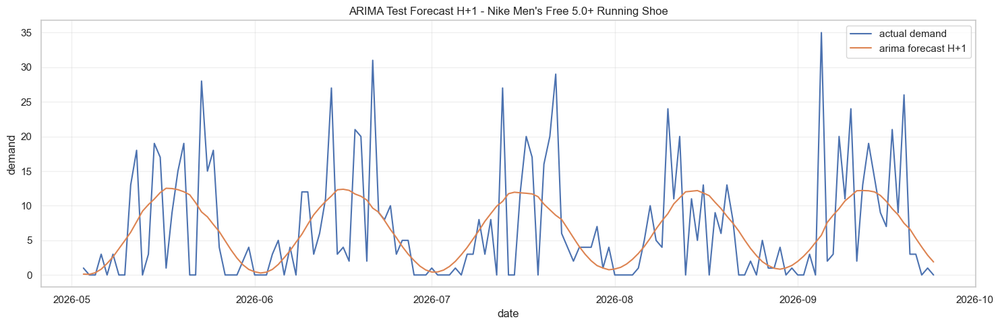

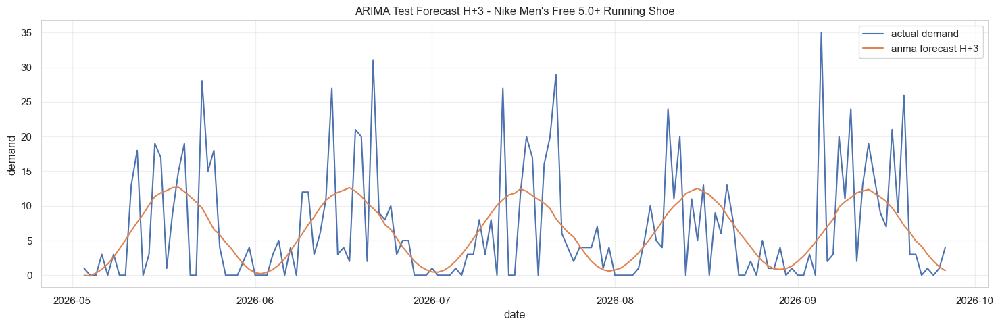

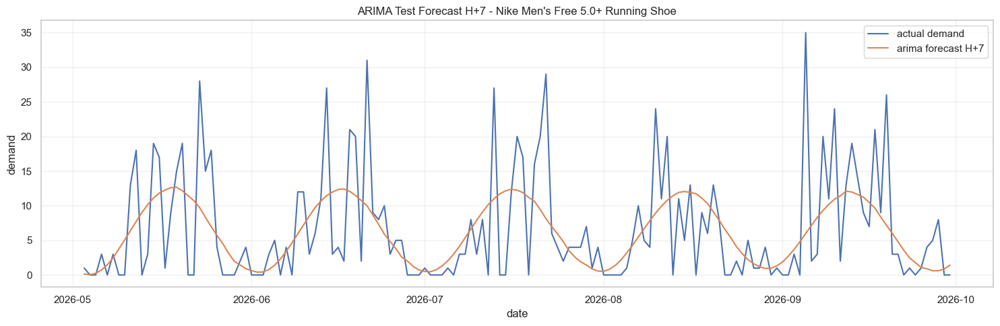

In [82]:
# menampilkan visualisasi hasil arima
for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        result = arima_test_results[product][horizon]

        plt.figure(figsize=(15, 5))

        plt.plot(
            result["date"],
            result["actual"],
            label="actual demand"
        )

        plt.plot(
            result["date"],
            result["prediction"],
            label=f"arima forecast H+{horizon}"
        )

        plt.title(
            f"ARIMA Test Forecast H+{horizon} - {product}"
        )

        plt.xlabel("date")
        plt.ylabel("demand")

        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# 09. Symbolic Regression Modeling

## Install dan Import Library

In [83]:
# install library symbolic regression
%pip install gplearn

                                              0.0/40.3 kB ? eta -:--:--
     -------------------------------------- 40.3/40.3 kB 969.7 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [84]:
# mengimpor library symbolic regression
from gplearn.genetic import SymbolicRegressor

# mengimpor library pendukung
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

## Menentukan Kandidat Hyperparameter

In [85]:
# menentukan kandidat hyperparameter symbolic regression
symbolic_candidates = [

    {
        "population_size": 100,
        "generations": 8,
        "tournament_size": 15,
        "parsimony_coefficient": 0.001
    },

    {
        "population_size": 200,
        "generations": 10,
        "tournament_size": 20,
        "parsimony_coefficient": 0.001
    }

]

print("jumlah kandidat:", len(symbolic_candidates))

jumlah kandidat: 2


## Membuat Fungsi Symbolic Regression

In [86]:
# membuat fungsi untuk symbolic regression
def create_symbolic_model(
    params,
    random_state=SEED
):

    symbolic_model = SymbolicRegressor(

        population_size=params["population_size"],

        generations=params["generations"],

        tournament_size=params["tournament_size"],

        parsimony_coefficient=params[
            "parsimony_coefficient"
        ],

        function_set=(
            "add",
            "sub",
            "mul",
            "div",
            "sqrt",
            "log",
            "abs",
            "neg"
        ),

        metric="mean absolute error",

        stopping_criteria=0.01,

        max_samples=0.9,

        random_state=random_state,

        n_jobs=1,

        verbose=0
    )

    pipeline = Pipeline([

        ("scaler", StandardScaler()),

        ("gp", symbolic_model)

    ])

    return pipeline


print("symbolic regression function berhasil dibuat")

symbolic regression function berhasil dibuat


## Hyperparameter Tuning dengan Walk-Forward Validation

In [87]:
# melakukan tuning symbolic regression
symbolic_best_params = {}
symbolic_tuning_results = []

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        train_data = direct_splits[
            product
        ][horizon]["train"]

        X_train, y_train = get_xy(
            train_data
        )

        candidate_scores = []

        for candidate_id, params in enumerate(
            symbolic_candidates,
            start=1
        ):

            model = create_symbolic_model(
                params,
                random_state=SEED + candidate_id
            )

            # menghitung skor walk-forward
            cv_mae = walk_forward_score(
                model,
                X_train,
                y_train
            )

            candidate_scores.append({
                "params": params,
                "cv_mae": cv_mae
            })

            symbolic_tuning_results.append({
                "Product": product,
                "Horizon": f"H+{horizon}",
                "Candidate": candidate_id,
                "CV MAE": cv_mae,
                "Parameters": params
            })

        # memilih kandidat dengan mae terendah
        best_candidate = min(
            candidate_scores,
            key=lambda x: x["cv_mae"]
        )

        symbolic_best_params[
            (product, horizon)
        ] = best_candidate["params"]

        print(
            f"{product} | H+{horizon} | "
            f"best CV MAE: {best_candidate['cv_mae']:.4f}"
        )


symbolic_tuning_results_df = pd.DataFrame(
    symbolic_tuning_results
)

display(symbolic_tuning_results_df)

Nike Men's Dri-FIT Victory Golf Polo | H+1 | best CV MAE: 8.4718
Nike Men's Dri-FIT Victory Golf Polo | H+3 | best CV MAE: 7.7135
Nike Men's Dri-FIT Victory Golf Polo | H+7 | best CV MAE: 8.2509
O'Brien Men's Neoprene Life Vest | H+1 | best CV MAE: 7.6561
O'Brien Men's Neoprene Life Vest | H+3 | best CV MAE: 7.9044
O'Brien Men's Neoprene Life Vest | H+7 | best CV MAE: 7.8521
Nike Men's Free 5.0+ Running Shoe | H+1 | best CV MAE: 5.6592
Nike Men's Free 5.0+ Running Shoe | H+3 | best CV MAE: 5.4209
Nike Men's Free 5.0+ Running Shoe | H+7 | best CV MAE: 5.6742


,Product,Horizon,Candidate,CV MAE,Parameters
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,1,9.19,"{'population_size': 100, 'generations': 8, 'to..."
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,2,8.47,"{'population_size': 200, 'generations': 10, 't..."
2,Nike Men's Dri-FIT Victory Golf Polo,H+3,1,7.71,"{'population_size': 100, 'generations': 8, 'to..."
3,Nike Men's Dri-FIT Victory Golf Polo,H+3,2,7.92,"{'population_size': 200, 'generations': 10, 't..."
4,Nike Men's Dri-FIT Victory Golf Polo,H+7,1,8.25,"{'population_size': 100, 'generations': 8, 'to..."
5,Nike Men's Dri-FIT Victory Golf Polo,H+7,2,9.57,"{'population_size': 200, 'generations': 10, 't..."
6,O'Brien Men's Neoprene Life Vest,H+1,1,7.84,"{'population_size': 100, 'generations': 8, 'to..."
7,O'Brien Men's Neoprene Life Vest,H+1,2,7.66,"{'population_size': 200, 'generations': 10, 't..."
8,O'Brien Men's Neoprene Life Vest,H+3,1,8.01,"{'population_size': 100, 'generations': 8, 'to..."
9,O'Brien Men's Neoprene Life Vest,H+3,2,7.90,"{'population_size': 200, 'generations': 10, 't..."


## Training dan Evaluasi Symbolic Regression

In [88]:
# melakukan training symbolic regression
symbolic_models = {}
symbolic_results = []

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        split = direct_splits[product][horizon]

        train_data = split["train"]
        validation_data = split["validation"]
        test_data = split["test"]

        X_train, y_train = get_xy(train_data)

        X_validation, y_validation = get_xy(
            validation_data
        )

        X_test, y_test = get_xy(test_data)

        best_params = symbolic_best_params[
            (product, horizon)
        ]

        # training awal menggunakan training set
        validation_model = create_symbolic_model(
            best_params
        )

        validation_model.fit(
            X_train,
            y_train
        )

        # prediksi validation
        validation_prediction = validation_model.predict(
            X_validation
        )

        validation_metrics = calculate_metrics(
            y_validation,
            validation_prediction
        )

        # menggabungkan training dan validation
        train_validation_data = pd.concat(
            [train_data, validation_data]
        ).sort_values("target_date")

        X_train_validation, y_train_validation = get_xy(
            train_validation_data
        )

        # training ulang menggunakan training dan validation
        final_model = create_symbolic_model(
            best_params
        )

        final_model.fit(
            X_train_validation,
            y_train_validation
        )

        # prediksi test
        test_prediction = final_model.predict(
            X_test
        )

        test_metrics = calculate_metrics(
            y_test,
            test_prediction
        )

        # menyimpan model final
        symbolic_models[
            (product, horizon)
        ] = final_model

        # menyimpan hasil evaluasi
        symbolic_results.append({

            "Product": product,

            "Horizon": f"H+{horizon}",

            "Validation MAE": validation_metrics["MAE"],

            "Validation RMSE": validation_metrics["RMSE"],

            "Validation WAPE": validation_metrics["WAPE"],

            "Test MAE": test_metrics["MAE"],

            "Test RMSE": test_metrics["RMSE"],

            "Test WAPE": test_metrics["WAPE"]

        })

        print(
            f"selesai: {product} | H+{horizon}"
        )


symbolic_results_df = pd.DataFrame(
    symbolic_results
)

display(symbolic_results_df)

selesai: Nike Men's Dri-FIT Victory Golf Polo | H+1
selesai: Nike Men's Dri-FIT Victory Golf Polo | H+3
selesai: Nike Men's Dri-FIT Victory Golf Polo | H+7
selesai: O'Brien Men's Neoprene Life Vest | H+1
selesai: O'Brien Men's Neoprene Life Vest | H+3
selesai: O'Brien Men's Neoprene Life Vest | H+7
selesai: Nike Men's Free 5.0+ Running Shoe | H+1
selesai: Nike Men's Free 5.0+ Running Shoe | H+3
selesai: Nike Men's Free 5.0+ Running Shoe | H+7


,Product,Horizon,Validation MAE,Validation RMSE,Validation WAPE,Test MAE,Test RMSE,Test WAPE
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,8.85,12.07,82.14,8.41,11.81,76.91
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,8.74,12.21,81.10,8.13,11.06,74.32
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,8.78,12.46,81.44,8.06,11.30,73.69
3,O'Brien Men's Neoprene Life Vest,H+1,7.73,10.72,75.19,8.07,10.58,85.58
4,O'Brien Men's Neoprene Life Vest,H+3,7.92,10.97,77.06,7.67,10.24,81.36
5,O'Brien Men's Neoprene Life Vest,H+7,7.87,10.65,76.62,7.56,9.98,80.21
6,Nike Men's Free 5.0+ Running Shoe,H+1,5.33,7.39,88.70,5.75,8.66,86.52
7,Nike Men's Free 5.0+ Running Shoe,H+3,5.43,7.76,90.22,5.38,7.93,80.88
8,Nike Men's Free 5.0+ Running Shoe,H+7,5.08,7.14,84.47,5.77,8.62,86.76


## Melihat Formula Hasil Genetic Programming

In [89]:
# menampilkan formula hasil symbolic regression
symbolic_formulas = []

for (product, horizon), model in symbolic_models.items():

    formula = str(
        model.named_steps["gp"]._program
    )

    symbolic_formulas.append({

        "Product": product,

        "Horizon": f"H+{horizon}",

        "Formula": formula

    })


symbolic_formulas_df = pd.DataFrame(
    symbolic_formulas
)

display(symbolic_formulas_df)

,Product,Horizon,Formula
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,"add(sqrt(log(abs(log(neg(mul(-0.023, sub(X14, ..."
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,abs(sqrt(abs(div(sqrt(abs(div(abs(log(neg(mul(...
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,"abs(sub(log(neg(mul(-0.023, X16))), sqrt(add(l..."
3,O'Brien Men's Neoprene Life Vest,H+1,"add(add(sqrt(log(mul(mul(-0.023, X16), sqrt(mu..."
4,O'Brien Men's Neoprene Life Vest,H+3,"add(neg(log(mul(mul(-0.023, X16), sqrt(sub(X10..."
5,O'Brien Men's Neoprene Life Vest,H+7,"add(abs(log(-0.023)), sqrt(add(abs(log(-0.023)..."
6,Nike Men's Free 5.0+ Running Shoe,H+1,"add(sqrt(log(mul(mul(-0.023, X16), sqrt(log(di..."
7,Nike Men's Free 5.0+ Running Shoe,H+3,"abs(add(log(neg(mul(-0.023, X16))), add(sub(X1..."
8,Nike Men's Free 5.0+ Running Shoe,H+7,"sqrt(add(log(neg(mul(-0.023, X16))), add(log(n..."


# 10. XGBoost Modeling

## Install dan Import XGBoost

In [ ]:
# install library xgboost
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [91]:
# mengimpor library xgboost
from xgboost import XGBRegressor

## Menentukan Kandidat Hyperparameter XGBoost

In [92]:
# menentukan kandidat hyperparameter xgboost
xgb_candidates = [

    {
        "n_estimators": 100,
        "max_depth": 3,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    },

    {
        "n_estimators": 200,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    },

    {
        "n_estimators": 200,
        "max_depth": 5,
        "learning_rate": 0.03,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 2
    }

]

print("jumlah kandidat:", len(xgb_candidates))

jumlah kandidat: 3


## Membuat Fungsi XGBoost

In [93]:
# membuat fungsi untuk xgboost
def create_xgb_model(params):

    model = XGBRegressor(

        objective="reg:squarederror",

        eval_metric="mae",

        tree_method="hist",

        n_jobs=-1,

        random_state=SEED,

        verbosity=0,

        **params

    )

    return model


print("xgboost function berhasil dibuat")

xgboost function berhasil dibuat


## Hyperparameter Tuning XGBoost

In [94]:
# melakukan tuning xgboost
xgb_best_params = {}
xgb_tuning_results = []

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        train_data = direct_splits[
            product
        ][horizon]["train"]

        X_train, y_train = get_xy(
            train_data
        )

        candidate_scores = []

        for candidate_id, params in enumerate(
            xgb_candidates,
            start=1
        ):

            model = create_xgb_model(
                params
            )

            # menghitung skor walk-forward
            cv_mae = walk_forward_score(
                model,
                X_train,
                y_train
            )

            candidate_scores.append({
                "params": params,
                "cv_mae": cv_mae
            })

            xgb_tuning_results.append({

                "Product": product,

                "Horizon": f"H+{horizon}",

                "Candidate": candidate_id,

                "CV MAE": cv_mae,

                "Parameters": params

            })

        # memilih kandidat dengan mae terendah
        best_candidate = min(
            candidate_scores,
            key=lambda x: x["cv_mae"]
        )

        xgb_best_params[
            (product, horizon)
        ] = best_candidate["params"]

        print(
            f"{product} | H+{horizon} | "
            f"best CV MAE: {best_candidate['cv_mae']:.4f}"
        )


xgb_tuning_results_df = pd.DataFrame(
    xgb_tuning_results
)

display(xgb_tuning_results_df)

Nike Men's Dri-FIT Victory Golf Polo | H+1 | best CV MAE: 8.8161
Nike Men's Dri-FIT Victory Golf Polo | H+3 | best CV MAE: 7.3722
Nike Men's Dri-FIT Victory Golf Polo | H+7 | best CV MAE: 8.0243
O'Brien Men's Neoprene Life Vest | H+1 | best CV MAE: 8.0949
O'Brien Men's Neoprene Life Vest | H+3 | best CV MAE: 7.5596
O'Brien Men's Neoprene Life Vest | H+7 | best CV MAE: 7.4264
Nike Men's Free 5.0+ Running Shoe | H+1 | best CV MAE: 6.0026
Nike Men's Free 5.0+ Running Shoe | H+3 | best CV MAE: 5.5240
Nike Men's Free 5.0+ Running Shoe | H+7 | best CV MAE: 5.4305


,Product,Horizon,Candidate,CV MAE,Parameters
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,1,8.93,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,2,10.40,"{'n_estimators': 200, 'max_depth': 3, 'learnin..."
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,3,8.82,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
3,Nike Men's Dri-FIT Victory Golf Polo,H+3,1,7.58,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,2,7.40,"{'n_estimators': 200, 'max_depth': 3, 'learnin..."
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,3,7.37,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
6,Nike Men's Dri-FIT Victory Golf Polo,H+7,1,8.12,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
7,Nike Men's Dri-FIT Victory Golf Polo,H+7,2,8.53,"{'n_estimators': 200, 'max_depth': 3, 'learnin..."
8,Nike Men's Dri-FIT Victory Golf Polo,H+7,3,8.02,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
9,O'Brien Men's Neoprene Life Vest,H+1,1,8.09,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."


## Training dan Evaluasi XGBoost

In [95]:
# melakukan training xgboost
xgb_models = {}
xgb_results = []

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        split = direct_splits[product][horizon]

        train_data = split["train"]
        validation_data = split["validation"]
        test_data = split["test"]

        X_train, y_train = get_xy(train_data)

        X_validation, y_validation = get_xy(
            validation_data
        )

        X_test, y_test = get_xy(test_data)

        best_params = xgb_best_params[
            (product, horizon)
        ]

        # training awal menggunakan training set
        validation_model = create_xgb_model(
            best_params
        )

        validation_model.fit(
            X_train,
            y_train
        )

        # prediksi validation
        validation_prediction = validation_model.predict(
            X_validation
        )

        validation_metrics = calculate_metrics(
            y_validation,
            validation_prediction
        )

        # menggabungkan training dan validation
        train_validation_data = pd.concat(
            [train_data, validation_data]
        ).sort_values("target_date")

        X_train_validation, y_train_validation = get_xy(
            train_validation_data
        )

        # training ulang menggunakan training dan validation
        final_model = create_xgb_model(
            best_params
        )

        final_model.fit(
            X_train_validation,
            y_train_validation
        )

        # prediksi test
        test_prediction = final_model.predict(
            X_test
        )

        test_metrics = calculate_metrics(
            y_test,
            test_prediction
        )

        # menyimpan model final
        xgb_models[
            (product, horizon)
        ] = final_model

        # menyimpan hasil evaluasi
        xgb_results.append({

            "Product": product,

            "Horizon": f"H+{horizon}",

            "Validation MAE": validation_metrics["MAE"],

            "Validation RMSE": validation_metrics["RMSE"],

            "Validation WAPE": validation_metrics["WAPE"],

            "Test MAE": test_metrics["MAE"],

            "Test RMSE": test_metrics["RMSE"],

            "Test WAPE": test_metrics["WAPE"]

        })

        print(
            f"selesai: {product} | H+{horizon}"
        )


xgb_results_df = pd.DataFrame(
    xgb_results
)

display(xgb_results_df)

selesai: Nike Men's Dri-FIT Victory Golf Polo | H+1
selesai: Nike Men's Dri-FIT Victory Golf Polo | H+3
selesai: Nike Men's Dri-FIT Victory Golf Polo | H+7
selesai: O'Brien Men's Neoprene Life Vest | H+1
selesai: O'Brien Men's Neoprene Life Vest | H+3
selesai: O'Brien Men's Neoprene Life Vest | H+7
selesai: Nike Men's Free 5.0+ Running Shoe | H+1
selesai: Nike Men's Free 5.0+ Running Shoe | H+3
selesai: Nike Men's Free 5.0+ Running Shoe | H+7


,Product,Horizon,Validation MAE,Validation RMSE,Validation WAPE,Test MAE,Test RMSE,Test WAPE
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,7.34,9.54,68.13,6.06,7.85,55.37
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,7.00,8.97,64.94,5.76,7.57,52.63
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,7.69,9.59,71.37,5.31,7.16,48.57
3,O'Brien Men's Neoprene Life Vest,H+1,7.40,9.21,71.99,6.46,7.90,68.48
4,O'Brien Men's Neoprene Life Vest,H+3,6.81,8.92,66.26,6.57,8.36,69.66
5,O'Brien Men's Neoprene Life Vest,H+7,6.94,8.80,67.49,6.25,7.73,66.26
6,Nike Men's Free 5.0+ Running Shoe,H+1,4.58,6.10,76.09,4.88,6.90,73.36
7,Nike Men's Free 5.0+ Running Shoe,H+3,4.61,6.02,76.61,4.69,6.47,70.56
8,Nike Men's Free 5.0+ Running Shoe,H+7,4.60,6.09,76.42,4.64,6.76,69.80


## Feature Importance XGBoost

In [96]:
# mengambil feature importance xgboost
feature_importance_results = []

for (product, horizon), model in xgb_models.items():

    importance = model.feature_importances_

    for feature, score in zip(
        FEATURE_COLUMNS,
        importance
    ):

        feature_importance_results.append({

            "Product": product,

            "Horizon": f"H+{horizon}",

            "Feature": feature,

            "Importance": score

        })


feature_importance_df = pd.DataFrame(
    feature_importance_results
)

# menghitung rata-rata importance untuk setiap produk
average_importance = (
    feature_importance_df
    .groupby(["Product", "Feature"])["Importance"]
    .mean()
    .reset_index()
    .sort_values(
        ["Product", "Importance"],
        ascending=[True, False]
    )
)

display(average_importance)

,Product,Feature,Importance
11,Nike Men's Dri-FIT Victory Golf Polo,rolling_mean_14,0.11
7,Nike Men's Dri-FIT Victory Golf Polo,lag_28,0.10
5,Nike Men's Dri-FIT Victory Golf Polo,lag_14,0.09
6,Nike Men's Dri-FIT Victory Golf Polo,lag_2,0.08
13,Nike Men's Dri-FIT Victory Golf Polo,rolling_mean_7,0.06
8,Nike Men's Dri-FIT Victory Golf Polo,lag_3,0.06
14,Nike Men's Dri-FIT Victory Golf Polo,rolling_std_14,0.06
9,Nike Men's Dri-FIT Victory Golf Polo,lag_7,0.06
4,Nike Men's Dri-FIT Victory Golf Polo,lag_1,0.06
16,Nike Men's Dri-FIT Victory Golf Polo,rolling_std_7,0.06


# 11. Random Forest Modeling

## Import Library Random Forest

In [97]:
# mengimpor library random forest
from sklearn.ensemble import RandomForestRegressor

## Menentukan Kandidat Hyperparameter Random Forest

In [98]:
# menentukan kandidat hyperparameter random forest
rf_candidates = [

    {
        "n_estimators": 200,
        "max_depth": 10,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": 1.0
    },

    {
        "n_estimators": 300,
        "max_depth": 15,
        "min_samples_split": 2,
        "min_samples_leaf": 2,
        "max_features": 0.8
    },

    {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 5,
        "min_samples_leaf": 2,
        "max_features": 0.8
    }

]

print("jumlah kandidat:", len(rf_candidates))

jumlah kandidat: 3


## Membuat Fungsi Random Forest

In [99]:
# membuat fungsi untuk random forest
def create_rf_model(params):

    model = RandomForestRegressor(

        random_state=SEED,

        n_jobs=-1,

        **params

    )

    return model


print("random forest function berhasil dibuat")

random forest function berhasil dibuat


## Hyperparameter Tuning Random Forest

In [100]:
# melakukan tuning random forest
rf_best_params = {}
rf_tuning_results = []

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        train_data = direct_splits[
            product
        ][horizon]["train"]

        X_train, y_train = get_xy(
            train_data
        )

        candidate_scores = []

        for candidate_id, params in enumerate(
            rf_candidates,
            start=1
        ):

            model = create_rf_model(
                params
            )

            # menghitung skor walk-forward
            cv_mae = walk_forward_score(
                model,
                X_train,
                y_train
            )

            candidate_scores.append({
                "params": params,
                "cv_mae": cv_mae
            })

            rf_tuning_results.append({

                "Product": product,

                "Horizon": f"H+{horizon}",

                "Candidate": candidate_id,

                "CV MAE": cv_mae,

                "Parameters": params

            })

        # memilih kandidat dengan mae terendah
        best_candidate = min(
            candidate_scores,
            key=lambda x: x["cv_mae"]
        )

        rf_best_params[
            (product, horizon)
        ] = best_candidate["params"]

        print(
            f"{product} | H+{horizon} | "
            f"best CV MAE: {best_candidate['cv_mae']:.4f}"
        )


rf_tuning_results_df = pd.DataFrame(
    rf_tuning_results
)

display(rf_tuning_results_df)

Nike Men's Dri-FIT Victory Golf Polo | H+1 | best CV MAE: 8.4814
Nike Men's Dri-FIT Victory Golf Polo | H+3 | best CV MAE: 7.9451
Nike Men's Dri-FIT Victory Golf Polo | H+7 | best CV MAE: 8.3584
O'Brien Men's Neoprene Life Vest | H+1 | best CV MAE: 7.7692
O'Brien Men's Neoprene Life Vest | H+3 | best CV MAE: 7.6757
O'Brien Men's Neoprene Life Vest | H+7 | best CV MAE: 7.6606
Nike Men's Free 5.0+ Running Shoe | H+1 | best CV MAE: 6.0301
Nike Men's Free 5.0+ Running Shoe | H+3 | best CV MAE: 5.5551
Nike Men's Free 5.0+ Running Shoe | H+7 | best CV MAE: 5.4367


,Product,Horizon,Candidate,CV MAE,Parameters
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,1,9.25,"{'n_estimators': 200, 'max_depth': 10, 'min_sa..."
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,2,8.48,"{'n_estimators': 300, 'max_depth': 15, 'min_sa..."
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,3,8.50,"{'n_estimators': 300, 'max_depth': None, 'min_..."
3,Nike Men's Dri-FIT Victory Golf Polo,H+3,1,8.18,"{'n_estimators': 200, 'max_depth': 10, 'min_sa..."
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,2,7.98,"{'n_estimators': 300, 'max_depth': 15, 'min_sa..."
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,3,7.95,"{'n_estimators': 300, 'max_depth': None, 'min_..."
6,Nike Men's Dri-FIT Victory Golf Polo,H+7,1,8.42,"{'n_estimators': 200, 'max_depth': 10, 'min_sa..."
7,Nike Men's Dri-FIT Victory Golf Polo,H+7,2,8.36,"{'n_estimators': 300, 'max_depth': 15, 'min_sa..."
8,Nike Men's Dri-FIT Victory Golf Polo,H+7,3,8.40,"{'n_estimators': 300, 'max_depth': None, 'min_..."
9,O'Brien Men's Neoprene Life Vest,H+1,1,8.51,"{'n_estimators': 200, 'max_depth': 10, 'min_sa..."


## Training dan Evaluasi Random Forest

In [101]:
# melakukan training random forest
rf_models = {}
rf_results = []

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        split = direct_splits[product][horizon]

        train_data = split["train"]
        validation_data = split["validation"]
        test_data = split["test"]

        X_train, y_train = get_xy(train_data)

        X_validation, y_validation = get_xy(
            validation_data
        )

        X_test, y_test = get_xy(test_data)

        best_params = rf_best_params[
            (product, horizon)
        ]

        # training awal menggunakan training set
        validation_model = create_rf_model(
            best_params
        )

        validation_model.fit(
            X_train,
            y_train
        )

        # prediksi validation
        validation_prediction = validation_model.predict(
            X_validation
        )

        validation_metrics = calculate_metrics(
            y_validation,
            validation_prediction
        )

        # menggabungkan training dan validation
        train_validation_data = pd.concat(
            [train_data, validation_data]
        ).sort_values("target_date")

        X_train_validation, y_train_validation = get_xy(
            train_validation_data
        )

        # training ulang menggunakan training dan validation
        final_model = create_rf_model(
            best_params
        )

        final_model.fit(
            X_train_validation,
            y_train_validation
        )

        # prediksi test
        test_prediction = final_model.predict(
            X_test
        )

        test_metrics = calculate_metrics(
            y_test,
            test_prediction
        )

        # menyimpan model final
        rf_models[
            (product, horizon)
        ] = final_model

        # menyimpan hasil evaluasi
        rf_results.append({

            "Product": product,

            "Horizon": f"H+{horizon}",

            "Validation MAE": validation_metrics["MAE"],

            "Validation RMSE": validation_metrics["RMSE"],

            "Validation WAPE": validation_metrics["WAPE"],

            "Test MAE": test_metrics["MAE"],

            "Test RMSE": test_metrics["RMSE"],

            "Test WAPE": test_metrics["WAPE"]

        })

        print(
            f"selesai: {product} | H+{horizon}"
        )


rf_results_df = pd.DataFrame(
    rf_results
)

display(rf_results_df)

selesai: Nike Men's Dri-FIT Victory Golf Polo | H+1
selesai: Nike Men's Dri-FIT Victory Golf Polo | H+3
selesai: Nike Men's Dri-FIT Victory Golf Polo | H+7
selesai: O'Brien Men's Neoprene Life Vest | H+1
selesai: O'Brien Men's Neoprene Life Vest | H+3
selesai: O'Brien Men's Neoprene Life Vest | H+7
selesai: Nike Men's Free 5.0+ Running Shoe | H+1
selesai: Nike Men's Free 5.0+ Running Shoe | H+3
selesai: Nike Men's Free 5.0+ Running Shoe | H+7


,Product,Horizon,Validation MAE,Validation RMSE,Validation WAPE,Test MAE,Test RMSE,Test WAPE
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,7.24,9.37,67.18,6.14,8.05,56.13
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,6.99,8.87,64.91,5.91,7.98,54.05
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,7.84,9.54,72.79,5.38,7.36,49.18
3,O'Brien Men's Neoprene Life Vest,H+1,7.53,9.32,73.27,6.27,7.73,66.51
4,O'Brien Men's Neoprene Life Vest,H+3,6.83,8.89,66.40,6.36,8.14,67.42
5,O'Brien Men's Neoprene Life Vest,H+7,6.91,8.72,67.26,6.12,7.62,64.89
6,Nike Men's Free 5.0+ Running Shoe,H+1,4.92,6.37,81.78,4.59,6.56,69.08
7,Nike Men's Free 5.0+ Running Shoe,H+3,4.71,6.03,78.25,4.52,6.29,68.02
8,Nike Men's Free 5.0+ Running Shoe,H+7,4.70,6.18,78.20,4.59,6.49,69.05


## Feature Importance Random Forest

In [102]:
# mengambil feature importance random forest
rf_feature_importance = []

for (product, horizon), model in rf_models.items():

    importance = model.feature_importances_

    for feature, score in zip(
        FEATURE_COLUMNS,
        importance
    ):

        rf_feature_importance.append({

            "Product": product,

            "Horizon": f"H+{horizon}",

            "Feature": feature,

            "Importance": score

        })


rf_feature_importance_df = pd.DataFrame(
    rf_feature_importance
)

# menghitung rata-rata importance untuk setiap produk
rf_average_importance = (
    rf_feature_importance_df
    .groupby(["Product", "Feature"])["Importance"]
    .mean()
    .reset_index()
    .sort_values(
        ["Product", "Importance"],
        ascending=[True, False]
    )
)

display(rf_average_importance)

,Product,Feature,Importance
11,Nike Men's Dri-FIT Victory Golf Polo,rolling_mean_14,0.14
7,Nike Men's Dri-FIT Victory Golf Polo,lag_28,0.11
6,Nike Men's Dri-FIT Victory Golf Polo,lag_2,0.09
5,Nike Men's Dri-FIT Victory Golf Polo,lag_14,0.08
4,Nike Men's Dri-FIT Victory Golf Polo,lag_1,0.07
8,Nike Men's Dri-FIT Victory Golf Polo,lag_3,0.06
14,Nike Men's Dri-FIT Victory Golf Polo,rolling_std_14,0.06
9,Nike Men's Dri-FIT Victory Golf Polo,lag_7,0.06
13,Nike Men's Dri-FIT Victory Golf Polo,rolling_mean_7,0.06
12,Nike Men's Dri-FIT Victory Golf Polo,rolling_mean_28,0.05


## Menggabungkan Hasil Evaluasi Keempat Model

In [103]:
# menggabungkan hasil evaluasi keempat model
arima_results_combined = arima_results_df.copy()
arima_results_combined["Model"] = "ARIMA"

symbolic_results_combined = symbolic_results_df.copy()
symbolic_results_combined["Model"] = "Symbolic Regression"

xgb_results_combined = xgb_results_df.copy()
xgb_results_combined["Model"] = "XGBoost"

rf_results_combined = rf_results_df.copy()
rf_results_combined["Model"] = "Random Forest"


# menyatukan seluruh hasil evaluasi
all_model_results_df = pd.concat(
    [
        arima_results_combined,
        symbolic_results_combined,
        xgb_results_combined,
        rf_results_combined
    ],
    ignore_index=True
)


# mengatur urutan kolom
all_model_results_df = all_model_results_df[

    [
        "Product",
        "Horizon",
        "Model",
        "Validation MAE",
        "Validation RMSE",
        "Validation WAPE",
        "Test MAE",
        "Test RMSE",
        "Test WAPE"
    ]

]


# mengurutkan hasil berdasarkan produk dan horizon
all_model_results_df = all_model_results_df.sort_values(
    ["Product", "Horizon", "Model"]
).reset_index(drop=True)


display(all_model_results_df)

,Product,Horizon,Model,Validation MAE,Validation RMSE,Validation WAPE,Test MAE,Test RMSE,Test WAPE
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,ARIMA,8.52,10.87,79.06,7.65,9.90,68.60
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,7.24,9.37,67.18,6.14,8.05,56.13
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,Symbolic Regression,8.85,12.07,82.14,8.41,11.81,76.91
3,Nike Men's Dri-FIT Victory Golf Polo,H+1,XGBoost,7.34,9.54,68.13,6.06,7.85,55.37
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,ARIMA,9.16,11.38,85.01,8.27,10.40,74.46
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,6.99,8.87,64.91,5.91,7.98,54.05
6,Nike Men's Dri-FIT Victory Golf Polo,H+3,Symbolic Regression,8.74,12.21,81.10,8.13,11.06,74.32
7,Nike Men's Dri-FIT Victory Golf Polo,H+3,XGBoost,7.00,8.97,64.94,5.76,7.57,52.63
8,Nike Men's Dri-FIT Victory Golf Polo,H+7,ARIMA,9.53,11.74,88.43,8.56,10.73,78.23
9,Nike Men's Dri-FIT Victory Golf Polo,H+7,Random Forest,7.84,9.54,72.79,5.38,7.36,49.18


## Menentukan Model Terbaik Berdasarkan Validation MAE

In [104]:
# mencari model terbaik berdasarkan validation mae
best_models_df = (
    all_model_results_df
    .sort_values("Validation MAE")
    .groupby(
        ["Product", "Horizon"],
        as_index=False
    )
    .first()
    .reset_index(drop=True)
)

display(best_models_df)

,Product,Horizon,Model,Validation MAE,Validation RMSE,Validation WAPE,Test MAE,Test RMSE,Test WAPE
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,7.24,9.37,67.18,6.14,8.05,56.13
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,6.99,8.87,64.91,5.91,7.98,54.05
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,XGBoost,7.69,9.59,71.37,5.31,7.16,48.57
3,Nike Men's Free 5.0+ Running Shoe,H+1,ARIMA,4.10,5.77,68.18,4.85,7.00,71.39
4,Nike Men's Free 5.0+ Running Shoe,H+3,ARIMA,4.12,5.77,68.46,4.79,6.92,71.00
5,Nike Men's Free 5.0+ Running Shoe,H+7,ARIMA,4.21,5.84,70.03,4.74,6.86,71.32
6,O'Brien Men's Neoprene Life Vest,H+1,XGBoost,7.40,9.21,71.99,6.46,7.90,68.48
7,O'Brien Men's Neoprene Life Vest,H+3,XGBoost,6.81,8.92,66.26,6.57,8.36,69.66
8,O'Brien Men's Neoprene Life Vest,H+7,Random Forest,6.91,8.72,67.26,6.12,7.62,64.89


# 12. Model Evaluation

## Membuat Fungsi Evaluasi Lengkap

In [105]:
# membuat fungsi evaluasi lengkap
def calculate_full_metrics(y_true, y_pred):

    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # menghitung mae
    mae = mean_absolute_error(
        y_true,
        y_pred
    )

    # menghitung rmse
    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_pred
        )
    )

    # menghitung wape
    total_actual = np.sum(
        np.abs(y_true)
    )

    if total_actual == 0:
        wape = np.nan
        bias = np.nan

    else:
        wape = (
            np.sum(np.abs(y_true - y_pred))
            / total_actual
        ) * 100

        # bias positif berarti overforecast
        bias = (
            np.sum(y_pred - y_true)
            / total_actual
        ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE": wape,
        "Bias": bias
    }


print("fungsi evaluasi lengkap berhasil dibuat")

fungsi evaluasi lengkap berhasil dibuat


## Mengumpulkan Prediksi Test Seluruh Model

In [106]:
# mengumpulkan hasil prediksi test seluruh model
evaluation_predictions = {}

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        test_data = direct_splits[
            product
        ][horizon]["test"]

        X_test, y_test = get_xy(test_data)

        # mengambil hasil prediksi symbolic regression
        symbolic_prediction = symbolic_models[
            (product, horizon)
        ].predict(X_test)

        # mengambil hasil prediksi xgboost
        xgb_prediction = xgb_models[
            (product, horizon)
        ].predict(X_test)

        # mengambil hasil prediksi random forest
        rf_prediction = rf_models[
            (product, horizon)
        ].predict(X_test)

        # menyimpan hasil prediksi setiap model
        predictions = {
            "Symbolic Regression": symbolic_prediction,
            "XGBoost": xgb_prediction,
            "Random Forest": rf_prediction
        }

        for model_name, prediction in predictions.items():

            evaluation_predictions[
                (product, horizon, model_name)
            ] = pd.DataFrame({

                "date": test_data["target_date"].values,

                "actual": y_test.values,

                "prediction": prediction

            })

        # mengambil hasil prediksi arima
        arima_prediction = arima_test_results[
            product
        ][horizon]

        evaluation_predictions[
            (product, horizon, "ARIMA")
        ] = arima_prediction.copy()


print("hasil prediksi test seluruh model berhasil dikumpulkan")
print(
    "total kombinasi evaluasi:",
    len(evaluation_predictions)
)

hasil prediksi test seluruh model berhasil dikumpulkan
total kombinasi evaluasi: 36


## Menghitung Metrik Evaluasi Seluruh Model

In [107]:
# menghitung metrik seluruh model
model_evaluation_results = []

for key, result in evaluation_predictions.items():

    product, horizon, model_name = key

    metrics = calculate_full_metrics(
        result["actual"],
        result["prediction"]
    )

    model_evaluation_results.append({

        "Product": product,

        "Horizon": f"H+{horizon}",

        "Model": model_name,

        "MAE": metrics["MAE"],

        "RMSE": metrics["RMSE"],

        "WAPE (%)": metrics["WAPE"],

        "Bias (%)": metrics["Bias"]

    })


model_evaluation_df = pd.DataFrame(
    model_evaluation_results
)

# mengurutkan hasil evaluasi
model_evaluation_df = model_evaluation_df.sort_values(
    ["Product", "Horizon", "Model"]
).reset_index(drop=True)

display(model_evaluation_df)

print("\ntotal kombinasi evaluasi:")
print(len(model_evaluation_df))

,Product,Horizon,Model,MAE,RMSE,WAPE (%),Bias (%)
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,ARIMA,7.65,9.90,68.60,-1.90
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,6.14,8.05,56.13,-8.40
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,Symbolic Regression,8.41,11.81,76.91,-40.55
3,Nike Men's Dri-FIT Victory Golf Polo,H+1,XGBoost,6.06,7.85,55.37,-3.21
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,ARIMA,8.27,10.40,74.46,-2.23
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,5.91,7.98,54.05,-7.99
6,Nike Men's Dri-FIT Victory Golf Polo,H+3,Symbolic Regression,8.13,11.06,74.32,-27.23
7,Nike Men's Dri-FIT Victory Golf Polo,H+3,XGBoost,5.76,7.57,52.63,-2.56
8,Nike Men's Dri-FIT Victory Golf Polo,H+7,ARIMA,8.56,10.73,78.23,-1.11
9,Nike Men's Dri-FIT Victory Golf Polo,H+7,Random Forest,5.38,7.36,49.18,-3.69



total kombinasi evaluasi:
36


## Visualisasi Perbandingan Forecast

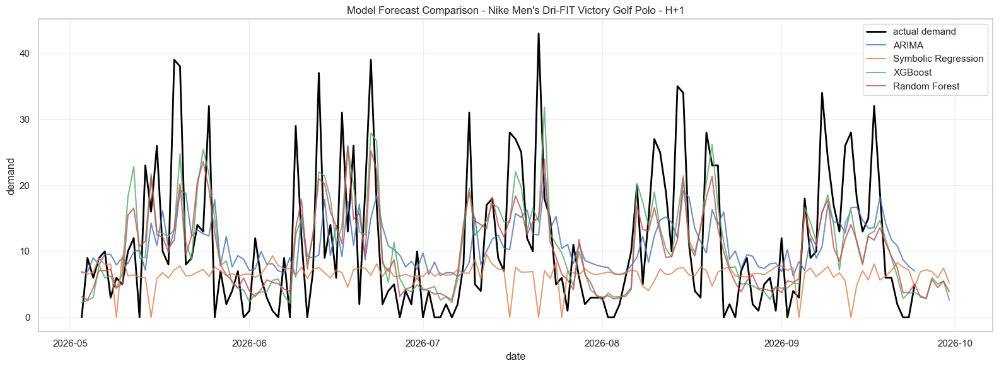

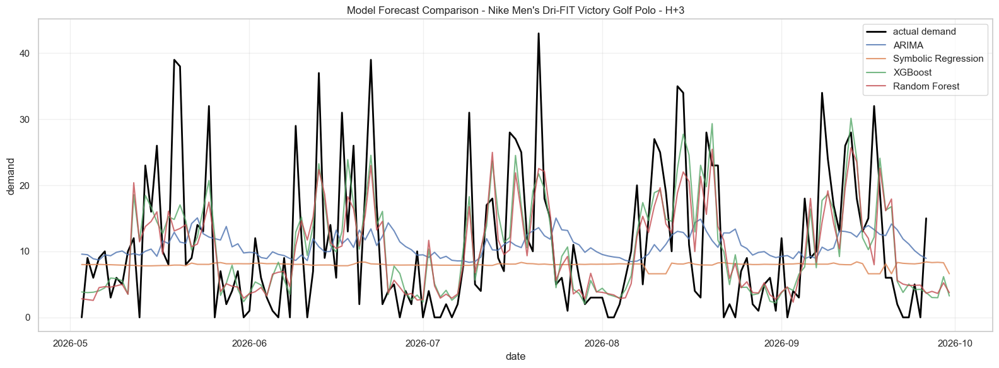

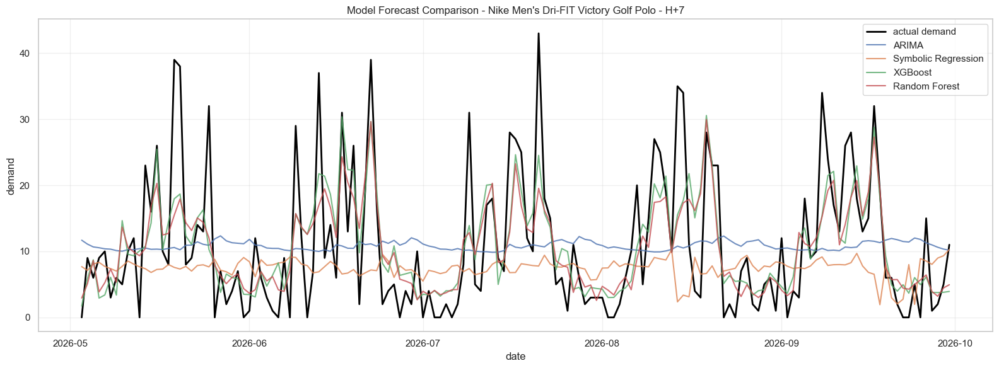

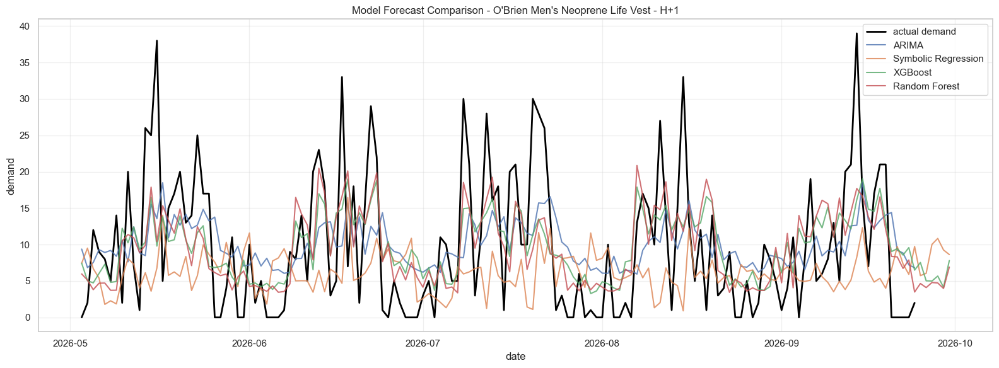

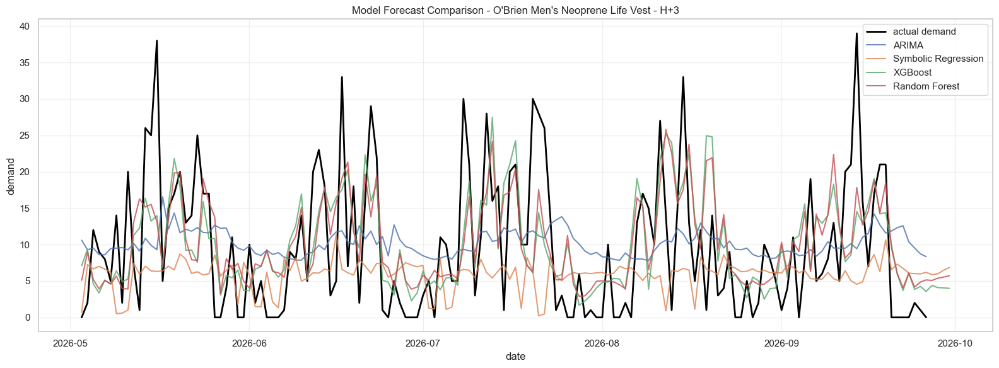

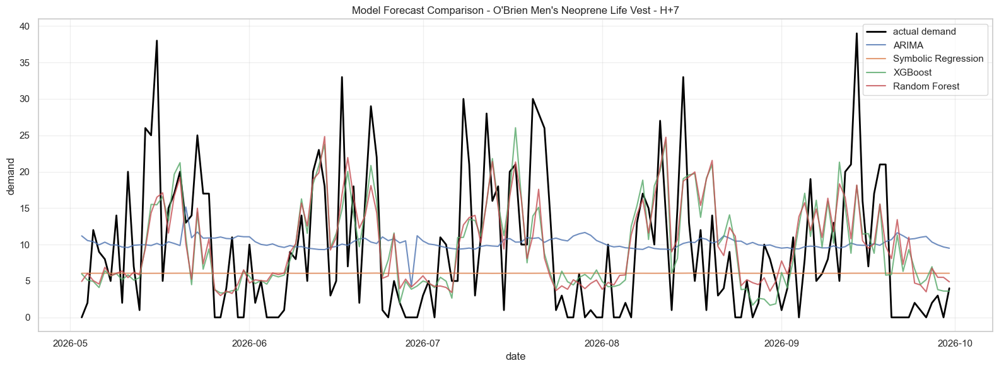

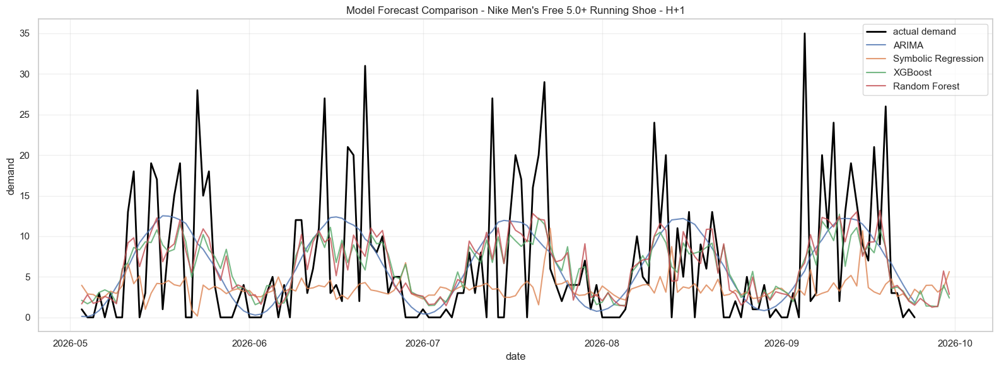

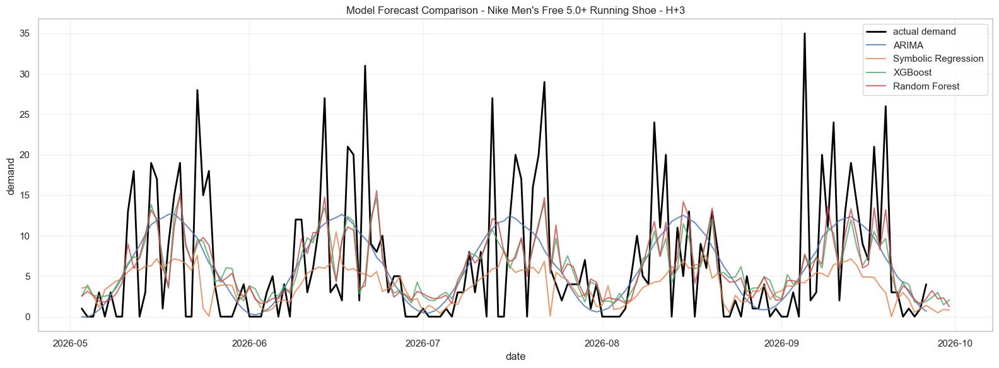

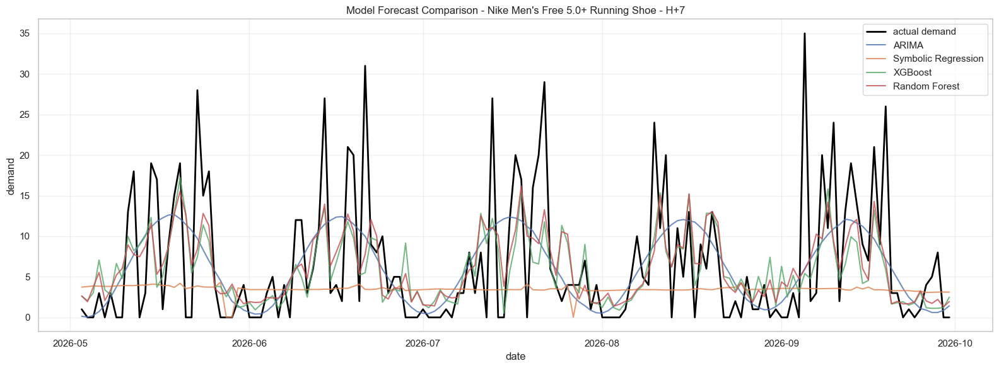

In [108]:
# membandingkan hasil forecast seluruh model
model_names = [
    "ARIMA",
    "Symbolic Regression",
    "XGBoost",
    "Random Forest"
]

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        plt.figure(figsize=(16, 6))

        # mengambil data aktual
        sample_result = evaluation_predictions[
            (product, horizon, "ARIMA")
        ]

        plt.plot(
            sample_result["date"],
            sample_result["actual"],
            label="actual demand",
            color="black",
            linewidth=2
        )

        # menampilkan prediksi setiap model
        for model_name in model_names:

            result = evaluation_predictions[
                (product, horizon, model_name)
            ]

            plt.plot(
                result["date"],
                result["prediction"],
                label=model_name,
                alpha=0.8
            )

        plt.title(
            f"Model Forecast Comparison - {product} - H+{horizon}"
        )

        plt.xlabel("date")
        plt.ylabel("demand")

        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

## Membandingkan Performa Model Berdasarkan Produk dan Horizon

In [109]:
# menampilkan perbandingan performa model
for product in PRODUCT_COLS:

    print("\n" + "=" * 80)
    print(f"produk: {product}")
    print("=" * 80)

    product_results = model_evaluation_df[
        model_evaluation_df["Product"] == product
    ].copy()

    display(
        product_results.sort_values(
            ["Horizon", "MAE"]
        )
    )


produk: Nike Men's Dri-FIT Victory Golf Polo


,Product,Horizon,Model,MAE,RMSE,WAPE (%),Bias (%)
3,Nike Men's Dri-FIT Victory Golf Polo,H+1,XGBoost,6.06,7.85,55.37,-3.21
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,6.14,8.05,56.13,-8.40
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,ARIMA,7.65,9.90,68.60,-1.90
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,Symbolic Regression,8.41,11.81,76.91,-40.55
7,Nike Men's Dri-FIT Victory Golf Polo,H+3,XGBoost,5.76,7.57,52.63,-2.56
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,5.91,7.98,54.05,-7.99
6,Nike Men's Dri-FIT Victory Golf Polo,H+3,Symbolic Regression,8.13,11.06,74.32,-27.23
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,ARIMA,8.27,10.40,74.46,-2.23
11,Nike Men's Dri-FIT Victory Golf Polo,H+7,XGBoost,5.31,7.16,48.57,-0.47
9,Nike Men's Dri-FIT Victory Golf Polo,H+7,Random Forest,5.38,7.36,49.18,-3.69



produk: O'Brien Men's Neoprene Life Vest


,Product,Horizon,Model,MAE,RMSE,WAPE (%),Bias (%)
25,O'Brien Men's Neoprene Life Vest,H+1,Random Forest,6.27,7.73,66.51,0.18
27,O'Brien Men's Neoprene Life Vest,H+1,XGBoost,6.46,7.90,68.48,2.68
24,O'Brien Men's Neoprene Life Vest,H+1,ARIMA,7.13,8.70,73.13,2.95
26,O'Brien Men's Neoprene Life Vest,H+1,Symbolic Regression,8.07,10.58,85.58,-33.31
29,O'Brien Men's Neoprene Life Vest,H+3,Random Forest,6.36,8.14,67.42,7.70
31,O'Brien Men's Neoprene Life Vest,H+3,XGBoost,6.57,8.36,69.66,6.38
28,O'Brien Men's Neoprene Life Vest,H+3,ARIMA,7.63,9.25,79.29,5.28
30,O'Brien Men's Neoprene Life Vest,H+3,Symbolic Regression,7.67,10.24,81.36,-37.53
33,O'Brien Men's Neoprene Life Vest,H+7,Random Forest,6.12,7.62,64.89,6.33
35,O'Brien Men's Neoprene Life Vest,H+7,XGBoost,6.25,7.73,66.26,4.67



produk: Nike Men's Free 5.0+ Running Shoe


,Product,Horizon,Model,MAE,RMSE,WAPE (%),Bias (%)
13,Nike Men's Free 5.0+ Running Shoe,H+1,Random Forest,4.59,6.56,69.08,-4.80
12,Nike Men's Free 5.0+ Running Shoe,H+1,ARIMA,4.85,7.00,71.39,-5.27
15,Nike Men's Free 5.0+ Running Shoe,H+1,XGBoost,4.88,6.90,73.36,-7.29
14,Nike Men's Free 5.0+ Running Shoe,H+1,Symbolic Regression,5.75,8.66,86.52,-46.13
17,Nike Men's Free 5.0+ Running Shoe,H+3,Random Forest,4.52,6.29,68.02,-7.58
19,Nike Men's Free 5.0+ Running Shoe,H+3,XGBoost,4.69,6.47,70.56,-8.83
16,Nike Men's Free 5.0+ Running Shoe,H+3,ARIMA,4.79,6.92,71.00,-5.86
18,Nike Men's Free 5.0+ Running Shoe,H+3,Symbolic Regression,5.38,7.93,80.88,-40.76
21,Nike Men's Free 5.0+ Running Shoe,H+7,Random Forest,4.59,6.49,69.05,-7.09
23,Nike Men's Free 5.0+ Running Shoe,H+7,XGBoost,4.64,6.76,69.80,-12.30


# 13. Best Model Selection

## Menggabungkan Hasil Validation Seluruh Model

In [110]:
# mengumpulkan hasil validation seluruh model
validation_results = []

# mengambil hasil validation arima
for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        result = arima_validation_results[
            product
        ][horizon]

        metrics = calculate_full_metrics(
            result["actual"],
            result["prediction"]
        )

        validation_results.append({

            "Product": product,

            "Horizon": f"H+{horizon}",

            "Model": "ARIMA",

            "Validation MAE": metrics["MAE"],

            "Validation RMSE": metrics["RMSE"],

            "Validation WAPE": metrics["WAPE"],

            "Validation Bias": metrics["Bias"]

        })


# mengambil hasil validation machine learning
ml_validation_sources = {

    "Symbolic Regression": (
        symbolic_models,
        symbolic_best_params
    ),

    "XGBoost": (
        xgb_models,
        xgb_best_params
    ),

    "Random Forest": (
        rf_models,
        rf_best_params
    )

}


for model_name, (models, params) in ml_validation_sources.items():

    for product in PRODUCT_COLS:

        for horizon in FORECAST_HORIZONS:

            split = direct_splits[product][horizon]

            validation_data = split["validation"]

            X_validation, y_validation = get_xy(
                validation_data
            )

            # membuat model validation dengan parameter terbaik
            if model_name == "Symbolic Regression":

                validation_model = create_symbolic_model(
                    params[(product, horizon)]
                )

            elif model_name == "XGBoost":

                validation_model = create_xgb_model(
                    params[(product, horizon)]
                )

            else:

                validation_model = create_rf_model(
                    params[(product, horizon)]
                )

            # melatih model menggunakan training set
            X_train, y_train = get_xy(
                split["train"]
            )

            validation_model.fit(
                X_train,
                y_train
            )

            # melakukan prediksi validation
            prediction = validation_model.predict(
                X_validation
            )

            metrics = calculate_full_metrics(
                y_validation,
                prediction
            )

            validation_results.append({

                "Product": product,

                "Horizon": f"H+{horizon}",

                "Model": model_name,

                "Validation MAE": metrics["MAE"],

                "Validation RMSE": metrics["RMSE"],

                "Validation WAPE": metrics["WAPE"],

                "Validation Bias": metrics["Bias"]

            })


validation_results_df = pd.DataFrame(
    validation_results
)

validation_results_df = validation_results_df.sort_values(
    ["Product", "Horizon", "Validation MAE"]
).reset_index(drop=True)

display(validation_results_df)

,Product,Horizon,Model,Validation MAE,Validation RMSE,Validation WAPE,Validation Bias
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,7.24,9.37,67.18,5.39
1,Nike Men's Dri-FIT Victory Golf Polo,H+1,XGBoost,7.34,9.54,68.13,2.43
2,Nike Men's Dri-FIT Victory Golf Polo,H+1,ARIMA,8.52,10.87,79.06,0.62
3,Nike Men's Dri-FIT Victory Golf Polo,H+1,Symbolic Regression,8.85,12.07,82.14,-31.55
4,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,6.99,8.87,64.91,9.62
5,Nike Men's Dri-FIT Victory Golf Polo,H+3,XGBoost,7.00,8.97,64.94,7.93
6,Nike Men's Dri-FIT Victory Golf Polo,H+3,Symbolic Regression,8.74,12.21,81.10,-34.54
7,Nike Men's Dri-FIT Victory Golf Polo,H+3,ARIMA,9.16,11.38,85.01,1.02
8,Nike Men's Dri-FIT Victory Golf Polo,H+7,XGBoost,7.69,9.59,71.37,12.60
9,Nike Men's Dri-FIT Victory Golf Polo,H+7,Random Forest,7.84,9.54,72.79,17.32


## Memilih Model Terbaik untuk Setiap Produk dan Horizon

In [111]:
# memilih model terbaik berdasarkan validation mae
best_models_df = (
    validation_results_df
    .sort_values("Validation MAE")
    .groupby(
        ["Product", "Horizon"],
        as_index=False
    )
    .first()
    .reset_index(drop=True)
)

display(best_models_df)

,Product,Horizon,Model,Validation MAE,Validation RMSE,Validation WAPE,Validation Bias
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,7.24,9.37,67.18,5.39
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,6.99,8.87,64.91,9.62
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,XGBoost,7.69,9.59,71.37,12.60
3,Nike Men's Free 5.0+ Running Shoe,H+1,ARIMA,4.10,5.77,68.18,3.27
4,Nike Men's Free 5.0+ Running Shoe,H+3,ARIMA,4.12,5.77,68.46,3.59
5,Nike Men's Free 5.0+ Running Shoe,H+7,ARIMA,4.21,5.84,70.03,3.93
6,O'Brien Men's Neoprene Life Vest,H+1,XGBoost,7.40,9.21,71.99,5.95
7,O'Brien Men's Neoprene Life Vest,H+3,XGBoost,6.81,8.92,66.26,-2.01
8,O'Brien Men's Neoprene Life Vest,H+7,Random Forest,6.91,8.72,67.26,9.59


## Ringkasan Model Terpilih

In [112]:
# membuat ringkasan model terpilih
best_model_summary = best_models_df[
    [
        "Product",
        "Horizon",
        "Model",
        "Validation MAE",
        "Validation RMSE",
        "Validation WAPE",
        "Validation Bias"
    ]
].copy()

display(best_model_summary)

print("\njumlah model terpilih:")
print(len(best_model_summary))

,Product,Horizon,Model,Validation MAE,Validation RMSE,Validation WAPE,Validation Bias
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest,7.24,9.37,67.18,5.39
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,Random Forest,6.99,8.87,64.91,9.62
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,XGBoost,7.69,9.59,71.37,12.60
3,Nike Men's Free 5.0+ Running Shoe,H+1,ARIMA,4.10,5.77,68.18,3.27
4,Nike Men's Free 5.0+ Running Shoe,H+3,ARIMA,4.12,5.77,68.46,3.59
5,Nike Men's Free 5.0+ Running Shoe,H+7,ARIMA,4.21,5.84,70.03,3.93
6,O'Brien Men's Neoprene Life Vest,H+1,XGBoost,7.40,9.21,71.99,5.95
7,O'Brien Men's Neoprene Life Vest,H+3,XGBoost,6.81,8.92,66.26,-2.01
8,O'Brien Men's Neoprene Life Vest,H+7,Random Forest,6.91,8.72,67.26,9.59



jumlah model terpilih:
9


# 14. Final Forecasting

## Membuat Future Features

In [113]:
# membuat fitur untuk forecasting periode mendatang
def create_future_features(
    series,
    horizon
):

    origin_date = series.index[-1]

    target_date = (
        origin_date
        + pd.Timedelta(days=horizon)
    )

    # membuat satu baris fitur
    features = {}

    # calendar features
    features["day_of_week"] = target_date.dayofweek
    features["day_of_month"] = target_date.day
    features["month"] = target_date.month
    features["day_of_year"] = target_date.dayofyear
    features["is_weekend"] = int(
        target_date.dayofweek >= 5
    )

    # lag features
    for lag in LAG_PERIODS:

        features[f"lag_{lag}"] = series.iloc[-lag + 1]

    # rolling statistics berdasarkan histori terakhir
    for window in ROLLING_WINDOWS:

        recent_data = series.iloc[-window:]

        features[f"rolling_mean_{window}"] = (
            recent_data.mean()
        )

        features[f"rolling_std_{window}"] = (
            recent_data.std()
        )

    # menyusun fitur sesuai urutan training
    future_data = pd.DataFrame(
        [features],
        columns=FEATURE_COLUMNS
    )

    return future_data, target_date


print("future feature function berhasil dibuat")

future feature function berhasil dibuat


## Melatih Ulang Model Terpilih dengan Seluruh Data

In [114]:
# menyiapkan model final
final_ml_models = {}
final_arima_models = {}

for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        selected_model = best_models_df.loc[

            (
                best_models_df["Product"] == product
            )
            &
            (
                best_models_df["Horizon"] == f"H+{horizon}"
            ),

            "Model"

        ].iloc[0]

        # mengambil dataset historis seluruh periode
        full_data = direct_datasets[
            product
        ][horizon]

        X_full, y_full = get_xy(
            full_data
        )

        # melatih ulang model machine learning terpilih
        if selected_model == "Symbolic Regression":

            model = create_symbolic_model(
                symbolic_best_params[(product, horizon)]
            )

            model.fit(
                X_full,
                y_full
            )

            final_ml_models[
                (product, horizon)
            ] = model

        elif selected_model == "XGBoost":

            model = create_xgb_model(
                xgb_best_params[(product, horizon)]
            )

            model.fit(
                X_full,
                y_full
            )

            final_ml_models[
                (product, horizon)
            ] = model

        elif selected_model == "Random Forest":

            model = create_rf_model(
                rf_best_params[(product, horizon)]
            )

            model.fit(
                X_full,
                y_full
            )

            final_ml_models[
                (product, horizon)
            ] = model

        elif selected_model == "ARIMA":

            # arima akan di-fit satu kali per produk
            if product not in final_arima_models:

                series = model_daily_wide[product]

                order = best_arima_orders[product]

                arima_model = ARIMA(
                    series,
                    order=order
                )

                final_arima_models[product] = (
                    arima_model.fit()
                )


print("final model berhasil dilatih ulang")

final model berhasil dilatih ulang


## Menghasilkan Final Forecast

In [115]:
# membuat final forecast
final_forecasts = []

for product in PRODUCT_COLS:

    # membuat forecast arima sampai tujuh hari jika diperlukan
    arima_forecast = None

    if product in final_arima_models:

        arima_forecast = final_arima_models[
            product
        ].forecast(
            steps=max(FORECAST_HORIZONS)
        )

    for horizon in FORECAST_HORIZONS:

        selected_row = best_models_df[

            (
                best_models_df["Product"] == product
            )
            &
            (
                best_models_df["Horizon"] == f"H+{horizon}"
            )

        ].iloc[0]

        selected_model = selected_row["Model"]

        # menentukan fitur untuk tanggal mendatang
        series = model_daily_wide[product]

        future_X, target_date = create_future_features(
            series,
            horizon
        )

        # mengambil prediksi dari model terpilih
        if selected_model == "ARIMA":

            prediction = float(
                arima_forecast.iloc[horizon - 1]
            )

        else:

            model = final_ml_models[
                (product, horizon)
            ]

            prediction = float(
                model.predict(future_X)[0]
            )

        final_forecasts.append({

            "Product": product,

            "Forecast Date": target_date,

            "Horizon": f"H+{horizon}",

            "Selected Model": selected_model,

            "Forecast Demand": prediction,

            "Forecast Demand Rounded": max(
                0,
                int(np.ceil(prediction))
            )

        })


final_forecast_df = pd.DataFrame(
    final_forecasts
)

display(final_forecast_df)

,Product,Forecast Date,Horizon,Selected Model,Forecast Demand,Forecast Demand Rounded
0,Nike Men's Dri-FIT Victory Golf Polo,2026-10-01,H+1,Random Forest,5.29,6
1,Nike Men's Dri-FIT Victory Golf Polo,2026-10-03,H+3,Random Forest,3.45,4
2,Nike Men's Dri-FIT Victory Golf Polo,2026-10-07,H+7,XGBoost,13.84,14
3,O'Brien Men's Neoprene Life Vest,2026-10-01,H+1,XGBoost,4.78,5
4,O'Brien Men's Neoprene Life Vest,2026-10-03,H+3,XGBoost,14.10,15
5,O'Brien Men's Neoprene Life Vest,2026-10-07,H+7,Random Forest,17.60,18
6,Nike Men's Free 5.0+ Running Shoe,2026-10-01,H+1,ARIMA,2.49,3
7,Nike Men's Free 5.0+ Running Shoe,2026-10-03,H+3,ARIMA,4.61,5
8,Nike Men's Free 5.0+ Running Shoe,2026-10-07,H+7,ARIMA,9.37,10


## Membuat Future Features

In [116]:
# membuat fitur untuk forecasting periode mendatang
def create_future_features(
    series,
    horizon
):

    origin_date = series.index[-1]

    target_date = (
        origin_date
        + pd.Timedelta(days=horizon)
    )

    # menyiapkan fitur
    features = {}

    # calendar features
    features["day_of_week"] = target_date.dayofweek
    features["day_of_month"] = target_date.day
    features["month"] = target_date.month
    features["day_of_year"] = target_date.dayofyear
    features["is_weekend"] = int(
        target_date.dayofweek >= 5
    )

    # lag features berdasarkan histori terakhir
    for lag in LAG_PERIODS:

        features[f"lag_{lag}"] = series.iloc[-lag]

    # rolling statistics berdasarkan histori terakhir
    for window in ROLLING_WINDOWS:

        recent_data = series.iloc[-window:]

        features[f"rolling_mean_{window}"] = (
            recent_data.mean()
        )

        features[f"rolling_std_{window}"] = (
            recent_data.std()
        )

    # menyusun fitur sesuai urutan training
    future_data = pd.DataFrame(
        [features],
        columns=FEATURE_COLUMNS
    )

    return future_data, target_date


print("future feature function berhasil dibuat")

future feature function berhasil dibuat


# 15. Forecast Uncertainty

## Menghitung Forecast Error Distribution

In [117]:
# mengumpulkan forecast error model terpilih
forecast_errors = []

for _, row in best_models_df.iterrows():

    product = row["Product"]

    horizon = int(
        row["Horizon"].replace("H+", "")
    )

    model_name = row["Model"]

    # mengambil prediksi test model terpilih
    result = evaluation_predictions[
        (product, horizon, model_name)
    ].copy()

    # menghitung forecast error
    result["Error"] = (
        result["actual"] - result["prediction"]
    )

    result["Product"] = product
    result["Horizon"] = f"H+{horizon}"
    result["Model"] = model_name

    forecast_errors.append(result)


forecast_errors_df = pd.concat(
    forecast_errors,
    ignore_index=True
)

display(forecast_errors_df.head())

print("\ntotal forecast error:")
print(len(forecast_errors_df))

,date,actual,prediction,Error,Product,Horizon,Model
0,2026-05-03,0.00,3.14,-3.14,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest
1,2026-05-04,9.00,2.63,6.37,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest
2,2026-05-05,6.00,4.49,1.51,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest
3,2026-05-06,9.00,7.10,1.90,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest
4,2026-05-07,10.00,7.08,2.92,Nike Men's Dri-FIT Victory Golf Polo,H+1,Random Forest



total forecast error:
1349


## Menghitung Statistik Forecast Error

In [118]:
# menghitung statistik forecast error
forecast_uncertainty_summary = []

for (product, horizon), group in forecast_errors_df.groupby(
    ["Product", "Horizon"]
):

    errors = group["Error"]

    forecast_uncertainty_summary.append({

        "Product": product,

        "Horizon": horizon,

        "Mean Error": errors.mean(),

        "Error Std": errors.std(),

        "Error Variance": errors.var(),

        "Error P05": errors.quantile(0.05),

        "Error P25": errors.quantile(0.25),

        "Error P50": errors.quantile(0.50),

        "Error P75": errors.quantile(0.75),

        "Error P95": errors.quantile(0.95)

    })


forecast_uncertainty_df = pd.DataFrame(
    forecast_uncertainty_summary
)

display(forecast_uncertainty_df)

,Product,Horizon,Mean Error,Error Std,Error Variance,Error P05,Error P25,Error P50,Error P75,Error P95
0,Nike Men's Dri-FIT Victory Golf Polo,H+1,0.92,8.03,64.44,-9.98,-4.50,-1.16,5.10,15.77
1,Nike Men's Dri-FIT Victory Golf Polo,H+3,0.87,7.96,63.31,-10.23,-3.79,-0.62,4.66,16.96
2,Nike Men's Dri-FIT Victory Golf Polo,H+7,0.05,7.18,51.59,-9.51,-4.03,-1.74,2.64,15.76
3,Nike Men's Free 5.0+ Running Shoe,H+1,0.36,7.02,49.21,-10.39,-3.38,-0.46,3.08,14.63
4,Nike Men's Free 5.0+ Running Shoe,H+3,0.40,6.93,48.06,-10.60,-3.09,-0.45,3.07,14.34
5,Nike Men's Free 5.0+ Running Shoe,H+7,0.48,6.86,47.12,-10.57,-2.91,-0.53,3.07,14.06
6,O'Brien Men's Neoprene Life Vest,H+1,-0.25,7.92,62.73,-9.91,-5.99,-2.27,5.03,14.52
7,O'Brien Men's Neoprene Life Vest,H+3,-0.60,8.36,69.95,-11.26,-5.58,-2.06,4.20,14.61
8,O'Brien Men's Neoprene Life Vest,H+7,-0.60,7.63,58.15,-11.22,-5.33,-2.51,3.90,14.41


## Visualisasi Distribusi Forecast Error

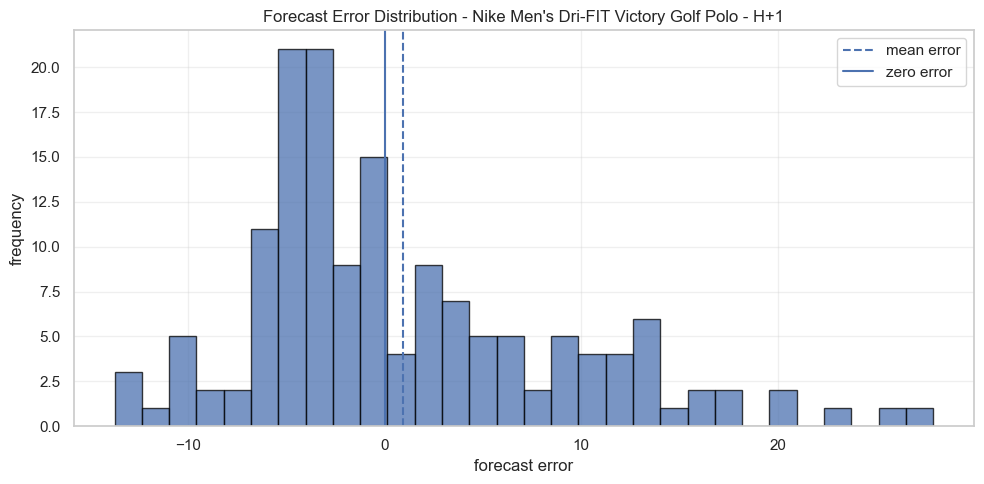

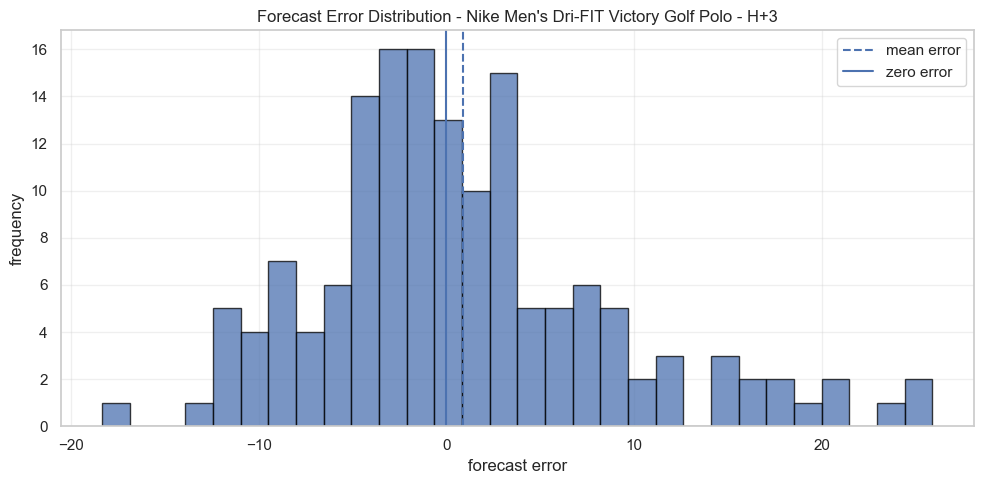

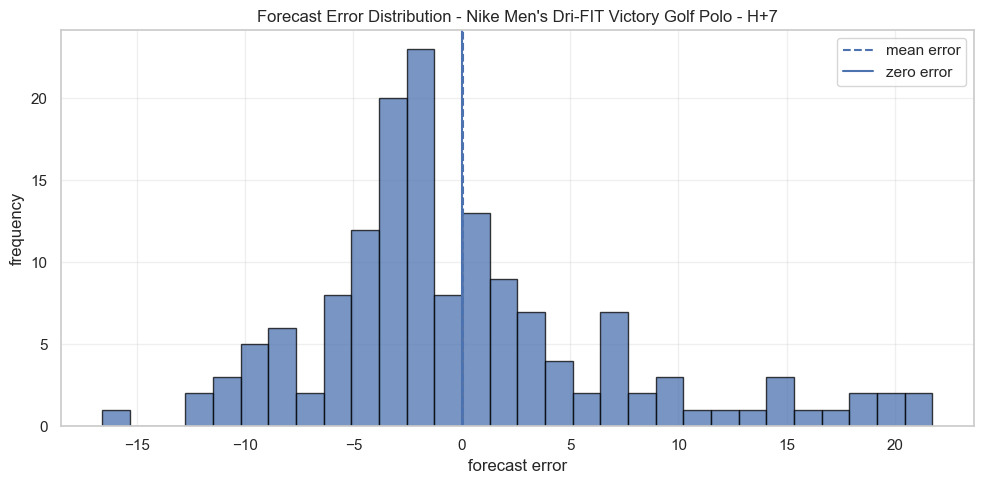

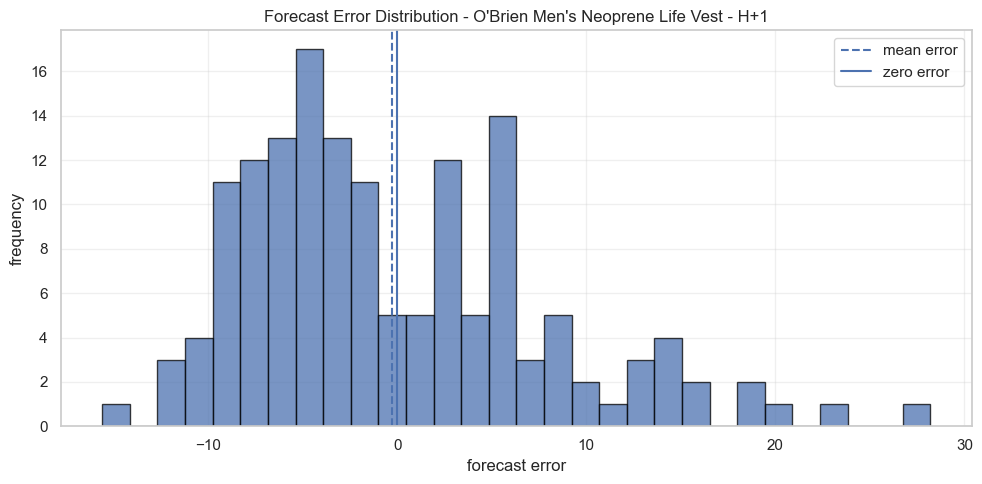

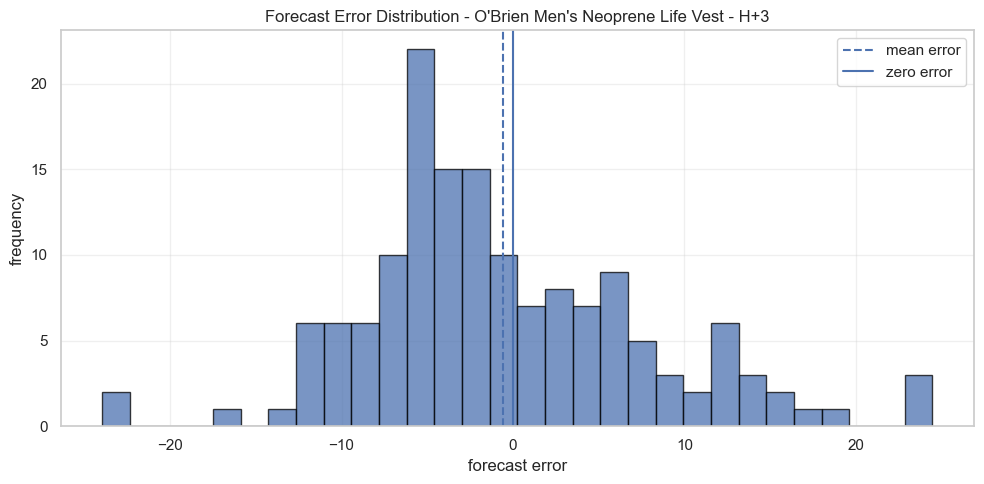

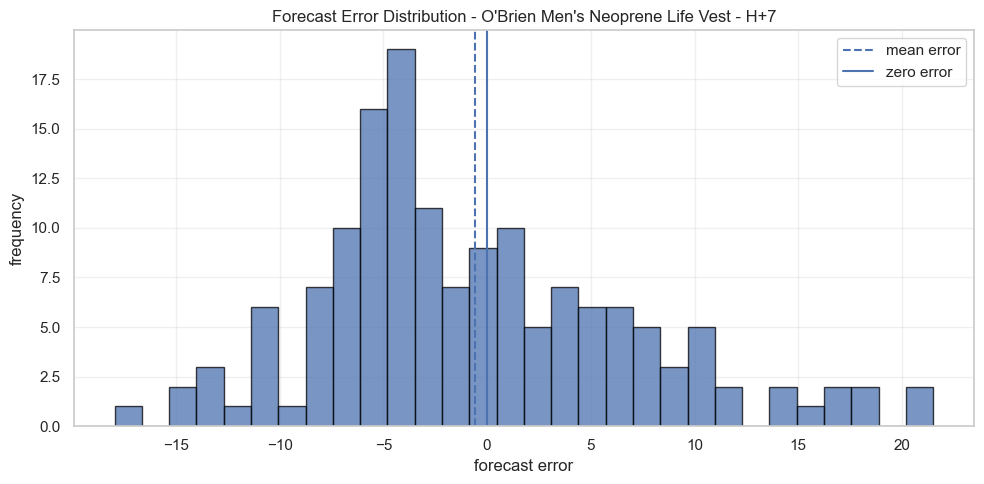

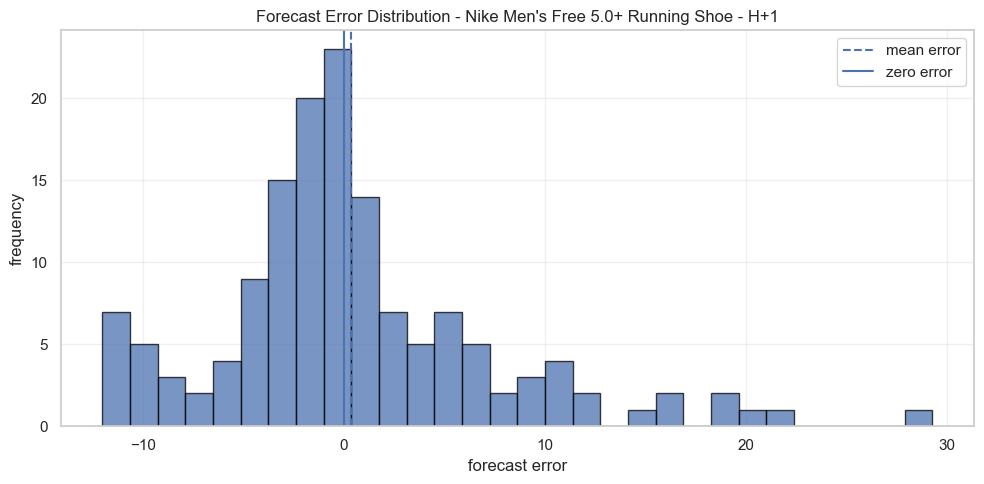

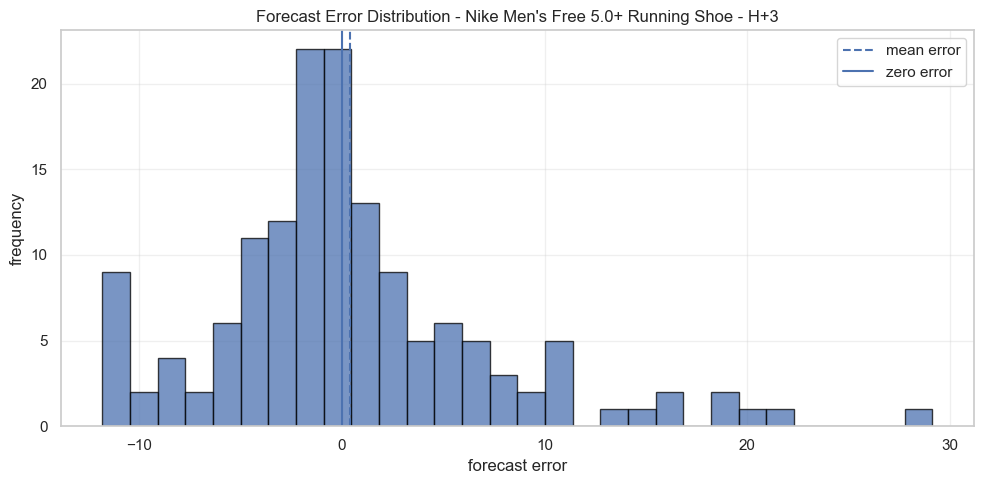

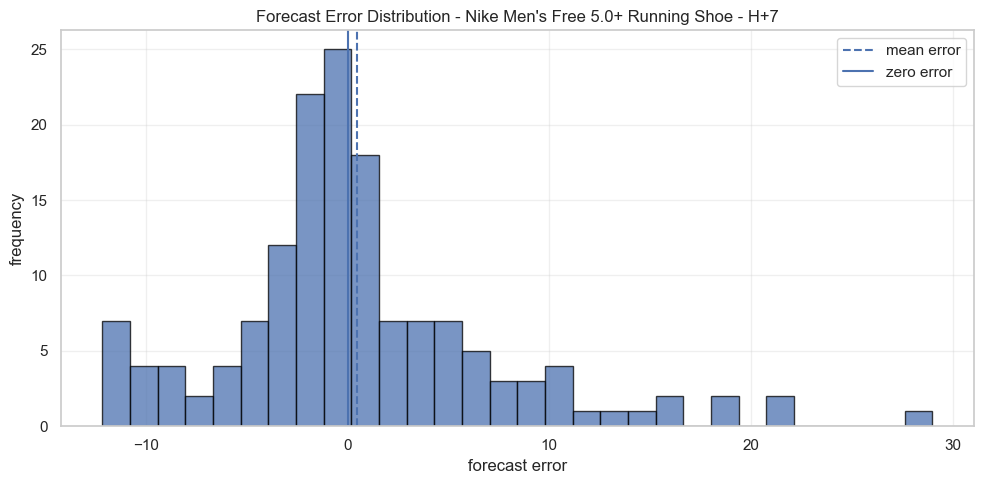

In [119]:
# melihat distribusi forecast error
for product in PRODUCT_COLS:

    for horizon in FORECAST_HORIZONS:

        error_data = forecast_errors_df[

            (
                forecast_errors_df["Product"] == product
            )
            &
            (
                forecast_errors_df["Horizon"] == f"H+{horizon}"
            )

        ]["Error"]

        plt.figure(figsize=(10, 5))

        plt.hist(
            error_data,
            bins=30,
            edgecolor="black",
            alpha=0.75
        )

        plt.axvline(
            error_data.mean(),
            linestyle="--",
            label="mean error"
        )

        plt.axvline(
            0,
            linestyle="-",
            label="zero error"
        )

        plt.title(
            f"Forecast Error Distribution - {product} - H+{horizon}"
        )

        plt.xlabel("forecast error")
        plt.ylabel("frequency")

        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

## Membuat Recursive Forecast untuk Lead-Time Demand

In [120]:
# membuat fungsi recursive forecast
def recursive_lead_time_forecast(
    product,
    origin_date,
    max_lead_time=7
):

    history = model_daily_wide.loc[
        :origin_date,
        product
    ].copy()

    # mengambil model terbaik untuk horizon satu hari
    selected_row = best_models_df[

        (
            best_models_df["Product"] == product
        )
        &
        (
            best_models_df["Horizon"] == "H+1"
        )

    ].iloc[0]

    selected_model = selected_row["Model"]

    forecast_values = []

    # mengambil prediksi tujuh hari ke depan
    if selected_model == "ARIMA":

        arima_model = ARIMA(
            history,
            order=best_arima_orders[product]
        ).fit()

        forecast_values = arima_model.forecast(
            steps=max_lead_time
        ).tolist()

    else:

        model_lookup = {

            "Symbolic Regression": symbolic_models,

            "XGBoost": xgb_models,

            "Random Forest": rf_models

        }

        model = model_lookup[
            selected_model
        ][(product, 1)]

        # melakukan prediksi secara berurutan
        for step in range(1, max_lead_time + 1):

            future_X, target_date = create_future_features(
                history,
                horizon=1
            )

            prediction = float(
                model.predict(future_X)[0]
            )

            forecast_values.append(
                prediction
            )

            # menambahkan prediksi ke histori sementara
            history.loc[target_date] = prediction

    return np.asarray(forecast_values)


print("recursive forecasting function berhasil dibuat")

recursive forecasting function berhasil dibuat


## Menghitung Lead-Time Demand Error Distribution

In [121]:
# menghitung lead-time demand error
lead_time_errors = []

MAX_LEAD_TIME = 7

test_start_date = validation_cutoff

last_origin_date = (
    MODEL_END_DATE
    - pd.Timedelta(days=MAX_LEAD_TIME)
)

for product in PRODUCT_COLS:

    # membuat daftar forecast origin
    origin_dates = model_daily_wide.loc[
        test_start_date:last_origin_date
    ].index

    for origin_date in origin_dates:

        # membuat forecast harian sampai tujuh hari
        predictions = recursive_lead_time_forecast(
            product=product,
            origin_date=origin_date,
            max_lead_time=MAX_LEAD_TIME
        )

        # mengambil demand aktual setelah origin
        actual_future = model_daily_wide.loc[
            origin_date + pd.Timedelta(days=1):
            origin_date + pd.Timedelta(days=MAX_LEAD_TIME),
            product
        ].values

        # menghitung error kumulatif setiap lead time
        for lead_time in range(1, MAX_LEAD_TIME + 1):

            actual_cumulative = np.sum(
                actual_future[:lead_time]
            )

            forecast_cumulative = np.sum(
                predictions[:lead_time]
            )

            error = (
                actual_cumulative
                - forecast_cumulative
            )

            lead_time_errors.append({

                "Product": product,

                "Origin Date": origin_date,

                "Lead Time": lead_time,

                "Actual Cumulative Demand": actual_cumulative,

                "Forecast Cumulative Demand": forecast_cumulative,

                "Lead Time Error": error

            })


lead_time_errors_df = pd.DataFrame(
    lead_time_errors
)

display(lead_time_errors_df.head(10))

print("\ntotal lead-time error observations:")
print(len(lead_time_errors_df))

c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\hp\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\hp\AppData

,Product,Origin Date,Lead Time,Actual Cumulative Demand,Forecast Cumulative Demand,Lead Time Error
0,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,1,0.00,3.14,-3.14
1,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,2,9.00,5.52,3.48
2,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,3,15.00,8.60,6.40
3,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,4,24.00,14.53,9.47
4,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,5,34.00,19.64,14.36
5,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,6,37.00,23.86,13.14
6,Nike Men's Dri-FIT Victory Golf Polo,2026-05-02,7,43.00,27.45,15.55
7,Nike Men's Dri-FIT Victory Golf Polo,2026-05-03,1,9.00,2.63,6.37
8,Nike Men's Dri-FIT Victory Golf Polo,2026-05-03,2,15.00,5.60,9.40
9,Nike Men's Dri-FIT Victory Golf Polo,2026-05-03,3,24.00,12.01,11.99



total lead-time error observations:
3045


## Menghitung Statistik Lead-Time Error

In [122]:
# menghitung statistik lead-time error
lead_time_uncertainty_summary = []

for (product, lead_time), group in lead_time_errors_df.groupby(
    ["Product", "Lead Time"]
):

    errors = group["Lead Time Error"]

    lead_time_uncertainty_summary.append({

        "Product": product,

        "Lead Time": lead_time,

        "Mean Error": errors.mean(),

        "Error Std": errors.std(),

        "Error Variance": errors.var(),

        "Error P05": errors.quantile(0.05),

        "Error P50": errors.quantile(0.50),

        "Error P90": errors.quantile(0.90),

        "Error P95": errors.quantile(0.95),

        "Error P99": errors.quantile(0.99)

    })


lead_time_uncertainty_df = pd.DataFrame(
    lead_time_uncertainty_summary
)

display(lead_time_uncertainty_df)

,Product,Lead Time,Mean Error,Error Std,Error Variance,Error P05,Error P50,Error P90,Error P95,Error P99
0,Nike Men's Dri-FIT Victory Golf Polo,1,0.90,8.10,65.55,-10.02,-1.16,12.88,15.93,24.60
1,Nike Men's Dri-FIT Victory Golf Polo,2,1.75,12.03,144.67,-14.37,-0.62,20.67,23.79,34.10
2,Nike Men's Dri-FIT Victory Golf Polo,3,2.81,15.24,232.40,-17.74,-0.46,24.47,30.90,42.30
3,Nike Men's Dri-FIT Victory Golf Polo,4,3.72,18.11,327.85,-22.53,0.90,29.02,36.83,45.92
4,Nike Men's Dri-FIT Victory Golf Polo,5,4.67,21.53,463.69,-28.05,3.26,33.56,43.63,54.51
5,Nike Men's Dri-FIT Victory Golf Polo,6,5.81,25.36,643.27,-33.64,0.95,44.41,52.27,62.53
6,Nike Men's Dri-FIT Victory Golf Polo,7,7.23,28.80,829.60,-35.48,2.80,49.10,61.85,71.01
7,Nike Men's Free 5.0+ Running Shoe,1,0.36,7.02,49.21,-10.39,-0.46,9.12,14.63,20.92
8,Nike Men's Free 5.0+ Running Shoe,2,0.72,9.41,88.57,-13.03,-0.68,13.56,18.03,25.32
9,Nike Men's Free 5.0+ Running Shoe,3,1.11,10.76,115.85,-13.52,0.21,14.54,22.28,34.47


## Visualisasi Lead-Time Error Distribution

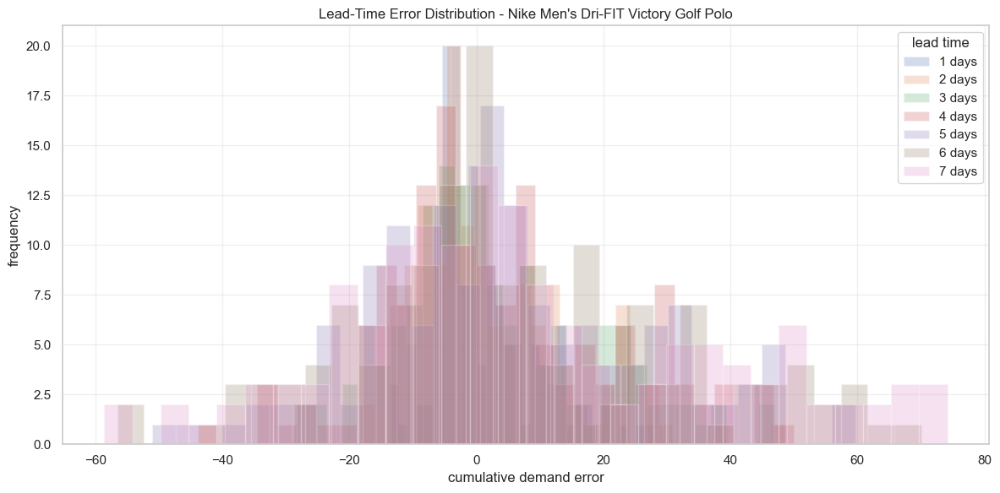

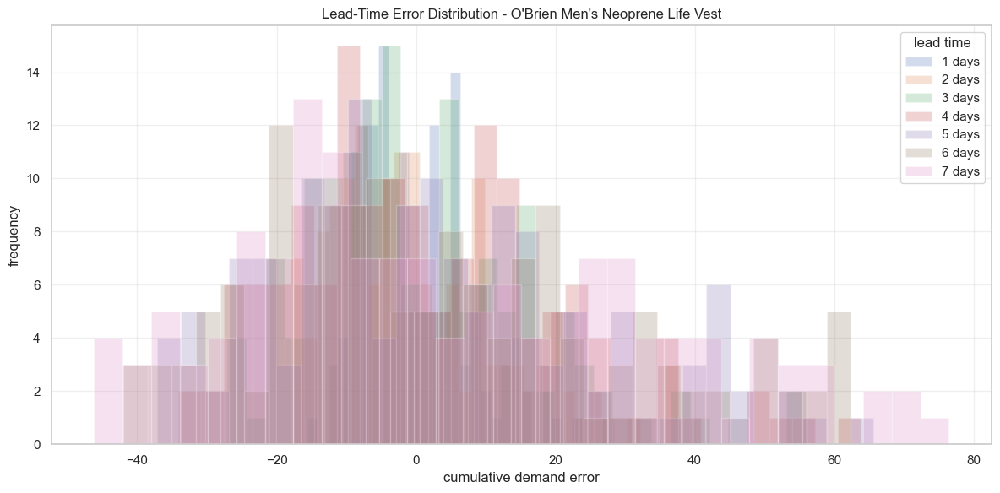

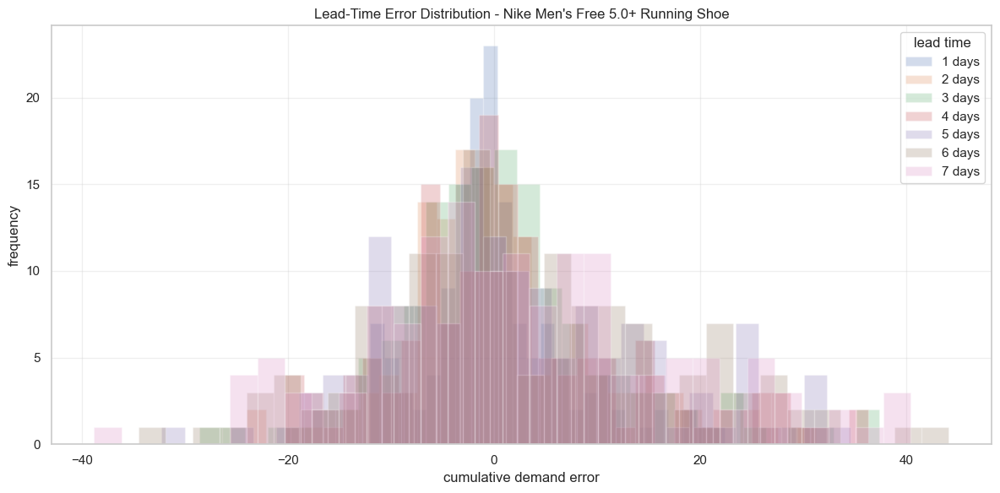

In [123]:
# melihat distribusi lead-time error
for product in PRODUCT_COLS:

    plt.figure(figsize=(12, 6))

    for lead_time in range(1, MAX_LEAD_TIME + 1):

        error_data = lead_time_errors_df[

            (
                lead_time_errors_df["Product"] == product
            )
            &
            (
                lead_time_errors_df["Lead Time"] == lead_time
            )

        ]["Lead Time Error"]

        plt.hist(
            error_data,
            bins=30,
            alpha=0.25,
            label=f"{lead_time} days"
        )

    plt.title(
        f"Lead-Time Error Distribution - {product}"
    )

    plt.xlabel("cumulative demand error")
    plt.ylabel("frequency")

    plt.legend(title="lead time")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# 16. Export Results

## Menyiapkan Folder Export

In [124]:
# mengimpor library untuk mengelola folder
import os

# membuat folder penyimpanan hasil
OUTPUT_DIR = "forecast_outputs"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

print("folder export berhasil disiapkan")
print("lokasi:", OUTPUT_DIR)

folder export berhasil disiapkan
lokasi: forecast_outputs


## Menyimpan Hasil Forecasting dan Evaluasi

In [125]:
# menyimpan hasil final forecasting
final_forecast_df.to_csv(
    f"{OUTPUT_DIR}/final_forecasts.csv",
    index=False
)

# menyimpan model terbaik
best_models_df.to_csv(
    f"{OUTPUT_DIR}/best_models.csv",
    index=False
)

# menyimpan hasil evaluasi seluruh model
model_evaluation_df.to_csv(
    f"{OUTPUT_DIR}/model_evaluation.csv",
    index=False
)

# menyimpan forecast error
forecast_errors_df.to_csv(
    f"{OUTPUT_DIR}/forecast_errors.csv",
    index=False
)

# menyimpan statistik forecast uncertainty
forecast_uncertainty_df.to_csv(
    f"{OUTPUT_DIR}/forecast_uncertainty.csv",
    index=False
)

# menyimpan lead-time error
lead_time_errors_df.to_csv(
    f"{OUTPUT_DIR}/lead_time_errors.csv",
    index=False
)

# menyimpan statistik lead-time uncertainty
lead_time_uncertainty_df.to_csv(
    f"{OUTPUT_DIR}/lead_time_uncertainty.csv",
    index=False
)

print("seluruh hasil berhasil disimpan")

seluruh hasil berhasil disimpan


## Memeriksa File Hasil Export

In [126]:
# memeriksa file hasil export
exported_files = os.listdir(
    OUTPUT_DIR
)

print("daftar file hasil export:\n")

for file_name in exported_files:

    file_path = os.path.join(
        OUTPUT_DIR,
        file_name
    )

    file_size = os.path.getsize(
        file_path
    ) / 1024

    print(
        f"{file_name} - {file_size:.2f} KB"
    )

daftar file hasil export:

best_models.csv - 1.15 KB
final_forecasts.csv - 0.79 KB
forecast_errors.csv - 134.24 KB
forecast_uncertainty.csv - 1.78 KB
lead_time_errors.csv - 269.99 KB
lead_time_uncertainty.csv - 3.96 KB
model_evaluation.csv - 4.43 KB


## Membuat Ringkasan Hasil Akhir

In [127]:
# menampilkan ringkasan hasil akhir
print("=" * 60)
print("FORECASTING PROCESS SUMMARY")
print("=" * 60)

print("\nperiode data:")
print(
    f"{model_daily_wide.index.min().date()} "
    f"hingga {model_daily_wide.index.max().date()}"
)

print("\nproduk:")
for product in PRODUCT_COLS:
    print(f"- {product}")

print("\nhorizon:")
for horizon in FORECAST_HORIZONS:
    print(f"- H+{horizon}")

print("\nmodel yang digunakan:")
for model_name in [
    "ARIMA",
    "Symbolic Regression",
    "XGBoost",
    "Random Forest"
]:
    print(f"- {model_name}")

print("\njumlah final forecast:")
print(len(final_forecast_df))

print("\njumlah model terpilih:")
print(len(best_models_df))

print("\njumlah forecast error:")
print(len(forecast_errors_df))

print("\njumlah lead-time error:")
print(len(lead_time_errors_df))

print("\nfolder export:")
print(OUTPUT_DIR)

print("\nforecasting process selesai!")

FORECASTING PROCESS SUMMARY

periode data:
2024-01-01 hingga 2026-09-30

produk:
- Nike Men's Dri-FIT Victory Golf Polo
- O'Brien Men's Neoprene Life Vest
- Nike Men's Free 5.0+ Running Shoe

horizon:
- H+1
- H+3
- H+7

model yang digunakan:
- ARIMA
- Symbolic Regression
- XGBoost
- Random Forest

jumlah final forecast:
9

jumlah model terpilih:
9

jumlah forecast error:
1349

jumlah lead-time error:
3045

folder export:
forecast_outputs

forecasting process selesai!
